# Is This Game Fun? Personalized Game Recommendation on Steam

**CSE 158/258, Assignment 2 (Fall 2026)**

**Team:** 
- Jeremy Shih
- Anvik Hsu
- Justin Shiu
- Liren Deng

## Overview

TEMP: "Fun" is not a column in any dataset, so we have to define it before we can predict it. We study
personalized game recommendation on the Steam "Australian users" dataset and compare two proxies for
whether a user finds a game fun: an **implicit** signal (how much the user played the game,
relative to how much that user plays games in general) and an **explicit** signal (whether the
user's review recommends the game). We compare popularity and random baselines with Bayesian
Personalized Ranking (BPR) trained on ownership, a **Fun-BPR** variant trained only to separate
heavily played owned games from barely played ones, and a latent factor model of log playtime. Then we
check whether the games our models consider "fun" agree with what users explicitly recommend.

TODO: replace this paragraph with a 3-4 sentence summary of the actual findings once results are in.

## Table of contents

0. Title & Overview (this section)
1. [Predictive Task](#1.-Predictive-Task)
2. [Exploratory Analysis & Preprocessing](#2.-Exploratory-Analysis-&-Preprocessing)
3. [Modeling](#3.-Modeling)
4. [Evaluation](#4.-Evaluation)
5. [Related Work](#5.-Related-Work)
6. [Conclusion](#6.-Conclusion)
7. [Export to HTML](#7.-Export-to-HTML)

Sections 1-5 map one-to-one onto the five graded rubric sections (5 marks each). Section 6 summarizes
and Section 7 is the submission checklist.

## Team conventions (delete before submitting)

- Names follow the lecture code style: `camelCase` variables (`itemsPerUser`, `usersPerItem`),
  `defaultdict` for lookups, TensorFlow `tf.keras.Model` subclasses for latent factor models.
- Every function has a docstring with `Parameters` / `Returns`.
- Do not hard-code numbers into markdown. Print them from code so the text cannot drift from the results.
- Data files live in `data/` (not committed). Paths are relative to this notebook.

In [1]:
import ast
import gzip
import os
import random
import re
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 158
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = 'data'
FILES = {
    'reviews': 'australian_user_reviews.json',
    'items': 'australian_users_items.json',
    'games': 'steam_games.json',
    'bundles': 'bundle_data.json',  # optional, not used yet
}

# Plot styling: one hue for single-series charts; a validated blue/orange pair when two series
# appear together. Grid and axes are kept recessive so the data carries the ink.
COLOR_PRIMARY = '#2a78d6'
COLOR_SECONDARY = '#eb6834'
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': '#52514e',
    'axes.labelcolor': '#0b0b0b',
    'axes.titlesize': 11,
    'axes.titleweight': 'bold',
    'axes.grid': True,
    'axes.axisbelow': True,
    'grid.color': '#e4e3df',
    'grid.linewidth': 0.6,
    'xtick.color': '#52514e',
    'ytick.color': '#52514e',
    'legend.frameon': False,
})
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

# 1. Predictive Task

**What this section is for.** Defining exactly what we predict, how we measure success, what we
compare against, and how we will know whether the predictions mean anything. Graders read this
first, so every later section should trace back to a sentence here.

**Rubric: 4 vs. 5.**
- *4:* The task is precise (inputs, outputs, label definition), the metrics and baselines are named
  and justified, and the validity check is stated.
- *5:* The definition of "fun" is motivated by evidence (link forward to the EDA in Section 2), the
  hypotheses are explicit and falsifiable, and we explain why the task is non-trivial (e.g. why
  popularity alone does well on ownership but should fail on "fun").

**TODO checklist**
- [x] Finalize the definition of "played a lot" (median vs. another quantile; include or exclude zero-playtime games)
- [x] State our hypotheses explicitly (H1, H2, ... below)
- [x] Confirm the hold-out sizes for the split (Section 3.1)
- [ ] Keep this section in sync with Sections 3 and 4

## 1.1 Task definition

Let $U$ be the set of users, $I$ the set of games, $I_u \subseteq I$ the games user $u$ owns, and
$t_{u,i}$ the total playtime (minutes) of user $u$ on game $i$.

We study three related tasks:

| | Task | Input | Output | Main metric |
|---|---|---|---|---|
| **A** | Ownership ranking | user $u$ | ranking of games $u$ does not yet own | AUC, Hit@10 |
| **B** | "Fun" ranking | user $u$, set of games $u$ owns | ranking of owned games by how much $u$ will enjoy them | AUC |
| **C** | Playtime regression | pair $(u, i)$ with $i \in I_u$ | $\log(1 + t_{u,i})$ | MSE |
| (D) | Recommend classification *(optional)* | review text (+ features) | `recommend` $\in \{0, 1\}$ | AUC, balanced accuracy |

**Why Task B is the hard one.** For Task A, just recommending popular games already works well:
a lot of people own Counter-Strike and Garry's Mod (Section 2.4). Task B is different. Both games
we compare are already in the user's library, so "how many people own it" says much less. The model
has to learn which games *this* user keeps coming back to. That's the gap Fun-BPR is built for.

## 1.2 Operationalizing "fun"

No dataset has a "fun" column, so we use two proxies for it.

**Implicit proxy: relative playtime.** Raw playtime doesn't compare well across users. Some people
put thousands of hours into games and others barely play at all. So we compare each game to the
user's own habits: a game is *played a lot* if the user played it more than their median game.

We take that median only over games the user has **actually played** ($t_{u,j} > 0$). Games with
0 minutes always count as *not played a lot*.

$$
y^{\text{play}}_{u,i} = \mathbb{1}\left[\, t_{u,i} > \operatorname{median}_{j \in I_u,\; t_{u,j} > 0} \, t_{u,j} \,\right], \qquad i \in I_u .
$$

Why we use the median and leave the zeros out:
- **Median:** it needs no tuning, and it adjusts to each user automatically. A stricter cutoff
  (like the top quartile) would leave fewer positives per user to train and test on.
- **Zeros out:** about a third of owned games were never played (Section 2.4). If we count them,
  a lot of users end up with a median of 0, and for them "played a lot" just means "played at all".
  Leaving them out fixes that.
- **Evidence:** leaving zeros out also lines up better with what people say in their reviews. The
  comparison is printed in Section 2.4 ("Do playtime and `recommend` agree?").
- **Cost:** a few more users don't have enough games of each kind for the split (Section 3.1).

**Explicit proxy: recommendation.** For (user, game) pairs that have a review,

$$
y^{\text{rec}}_{u,i} = \mathbb{1}\left[\, u \text{ recommends } i \,\right].
$$

The two can disagree. A grindy game can have tons of hours and still get a thumbs down, and a short
story game can be loved but finished in an afternoon. Section 2.4 shows where they disagree most,
and Section 4.6 checks whether our models' "fun" scores match `recommend`.

## 1.3 Hypotheses

Each one comes with the result in Section 4 that would prove it wrong.

- **H1:** Popularity is a strong baseline for Task A (ownership) but close to random for Task B,
  because in Task B both games are already owned.
  *Wrong if:* popularity's Task B AUC is clearly above 0.5.
- **H2:** Fun-BPR beats standard BPR on Task B, and standard BPR beats Fun-BPR on Task A.
  *Wrong if:* either gap goes the other way or isn't significant (Section 4.4).
- **H3:** Among games users reviewed, the ones Fun-BPR scores higher get recommended more often.
  *Wrong if:* Fun-BPR's AUC at separating recommended from not-recommended games (Section 4.6) isn't above 0.5.

## 1.4 Evaluation plan, baselines, validity

- **Metrics:** AUC and Hit@10 for ownership (Task A), AUC for fun (Task B), MSE on $\log(1+t)$ for
  playtime, and AUC plus balanced accuracy for `recommend`. Section 4.1 explains why.
- **Baselines:** random ranking, and popularity (by number of owners, and by total playtime).
- **Split:** per user, we hold out 1 high-play and 1 low-play game for validation, and the same for
  test (`nHoldout = 1`). A user needs at least 3 high-play and 3 low-play games, so there's still
  one of each left for training. Most users qualify (Section 3.1 prints the count). We never split
  on random rows, because that can leave a user with nothing to train on.
- **Validity:** (1) check model rankings against the real `recommend` labels on reviewed games;
  (2) look at where playtime and `recommend` disagree; (3) check that wins over the baselines are
  real and not luck: bootstrap confidence intervals over users, paired tests between models, and
  several random seeds (Section 4.4).

# 2. Exploratory Analysis & Preprocessing

**What this section is for.** Where the data comes from, what we did to it, and what it looks
like. Every preprocessing decision and every modeling choice later on should be justified by
something shown here.

**Rubric: 4 vs. 5.**
- *4:* Clear provenance (source, collection method, intended use), every processing step reported,
  and statistics, tables and plots that support the discussion.
- *5:* The EDA directly drives decisions, e.g. showing why playtime must be log-transformed and
  normalized per user, or quantifying how often playtime and `recommend` disagree. Data-quality issues
  (duplicates, missing years, reviews of unowned games) are found and handled deliberately.

**TODO checklist**
- [x] Verify the provenance paragraph against the dataset page and the papers in Section 5
- [x] Decide what to do with reviews of games that are not in the reviewer's library (Section 2.3, step 5)
- [x] Add a genre/tag plot from `steam_games.json` if it supports the story (done as a genre table in Section 2.4)
- [x] Write 1-2 sentences of interpretation under every plot

## 2.1 Data context

The data comes from Julian McAuley's recommender systems dataset collection
(<https://cseweb.ucsd.edu/~jmcauley/datasets.html#steam_data>). The user libraries and reviews we
use are the **"Version 1" Australian data**, introduced by Pathak, Gupta & McAuley (SIGIR 2017) for
bundle recommendation. They crawled the public profiles of users in the Australian **"GameAus"**
Steam community, which gave 88,310 users and 10,978 games. Those are exactly the raw counts we load
in Section 2.2. The 615 store bundles in `bundle_data.json` come from the same paper.

The other two papers the dataset page asks us to cite use the data differently:
- **Wan & McAuley (RecSys 2018)** reuse this same Australian data to model "purchase, play, review,
  recommend" chains. They also report that about 36% of purchased games are never played, which
  matches what we find in Section 2.4.
- **Kang & McAuley (ICDM 2018, SASRec)** introduce a much larger "Version 2" crawl (2.57M users,
  15,474 games, 7.79M reviews from Oct 2010 to Jan 2018). We don't use its reviews. Our
  `steam_games.json` looks like that version's item metadata (price, metascore, genres, developer).

**When was it collected?** None of the sources give a crawl date. Our dated reviews run up to the end
of 2015, and Steam leaves out the year for reviews posted in the current year (Section 2.3), so the
crawl most likely happened in 2016. Also note the SIGIR paper reports 902,967 game purchases, while
the file has about 5.1M (user, game) library rows. The paper doesn't say how purchases were counted,
so we just work with the full libraries as given.

| File | One record is... | Used for |
|---|---|---|
| `australian_users_items.json` | a user and their full library (`items`, each with `playtime_forever`, `playtime_2weeks`) | implicit feedback, Tasks A-C |
| `australian_user_reviews.json` | a user and their reviews (`reviews`, each with `item_id`, `recommend`, `review`, `posted`, ...) | explicit feedback, validity check, Task D |
| `steam_games.json` | one game's store metadata (`genres`, `tags`, `price`, `developer`, ...) | names and genres for interpretation |
| `bundle_data.json` *(optional)* | a store bundle and its games | not used yet |

All files are "loose JSON": every line is a **Python dict literal** (single quotes, `True`/`False`,
`u'...'` strings), so we parse each line with `ast.literal_eval` rather than `json.loads`.
Playtimes are in **minutes**, which is the Steam API convention.

## 2.2 Loading

In [2]:
def resolvePath(fileName, dataDir=DATA_DIR):
    """Find a data file, accepting either the plain or the gzipped version.

    Parameters
    ----------
    fileName : str
        File name without the `.gz` suffix, e.g. 'steam_games.json'.
    dataDir : str
        Directory containing the data files.

    Returns
    -------
    str
        Path to the existing file (plain preferred, otherwise `.gz`).
    """
    for candidate in (fileName, fileName + '.gz'):
        path = os.path.join(dataDir, candidate)
        if os.path.exists(path):
            return path
    raise FileNotFoundError(f'{fileName}(.gz) not found in {dataDir}/')


def readLooseJson(path):
    """Yield one record per line from a "loose JSON" (Python dict literal) file.

    Parameters
    ----------
    path : str
        Path to a `.json` or `.json.gz` file with one Python dict literal per line.

    Returns
    -------
    generator of dict
        Parsed records, in file order.
    """
    opener = gzip.open if path.endswith('.gz') else open
    with opener(path, 'rt', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if line:
                yield ast.literal_eval(line)


print(f'{"file":35s} {"size (MB)":>10s}')
for name in sorted(os.listdir(DATA_DIR)):
    print(f'{name:35s} {os.path.getsize(os.path.join(DATA_DIR, name)) / 1e6:10.1f}')

file                                 size (MB)
australian_user_reviews.json.gz            6.9
australian_users_items.json.gz            74.0
bundle_data.json.gz                        0.1
steam_games.json.gz                        2.7


In [3]:
def loadUserItems(path):
    """Flatten user libraries into one row per (user, game) pair.

    Duplicate user records are kept here (tagged by `line`) and removed in Section 2.3, so the
    cleaning step is visible.

    Parameters
    ----------
    path : str
        Path to `australian_users_items.json(.gz)`.

    Returns
    -------
    interactions : pd.DataFrame
        Columns: line, user_id, item_id, playtime_forever, playtime_2weeks.
    userLines : pd.DataFrame
        One row per line in the file. Columns: line, user_id, items_count, n_items.
    itemNames : dict
        item_id -> item_name as it appears in user libraries.
    """
    cols = defaultdict(list)
    userRows = []
    itemNames = {}
    for line, d in enumerate(readLooseJson(path)):
        userRows.append((line, d['user_id'], d['items_count'], len(d['items'])))
        for it in d['items']:
            cols['line'].append(line)
            cols['user_id'].append(d['user_id'])
            cols['item_id'].append(it['item_id'])
            cols['playtime_forever'].append(it['playtime_forever'])
            cols['playtime_2weeks'].append(it['playtime_2weeks'])
            itemNames[it['item_id']] = it['item_name']
    interactions = pd.DataFrame(cols)
    userLines = pd.DataFrame(userRows, columns=['line', 'user_id', 'items_count', 'n_items'])
    return interactions, userLines, itemNames


def loadReviews(path):
    """Flatten user review records into one row per review.

    Parameters
    ----------
    path : str
        Path to `australian_user_reviews.json(.gz)`.

    Returns
    -------
    pd.DataFrame
        Columns: line, user_id, item_id, recommend, review, posted, last_edited, funny, helpful.
    """
    rows = []
    for line, d in enumerate(readLooseJson(path)):
        for r in d['reviews']:
            rows.append({'line': line, 'user_id': d['user_id'], **r})
    return pd.DataFrame(rows)


def loadGames(path):
    """Load game metadata into a DataFrame (one row per record; fields can be missing).

    Parameters
    ----------
    path : str
        Path to `steam_games.json(.gz)`.

    Returns
    -------
    pd.DataFrame
        One row per game record. Missing fields are NaN.
    """
    return pd.DataFrame(list(readLooseJson(path)))

In [5]:
# The items file is ~550 MB; parsing it with ast.literal_eval takes a minute or two.
interactionsRaw, userLines, itemNames = loadUserItems(resolvePath(FILES['items']))
reviewsRaw = loadReviews(resolvePath(FILES['reviews']))
games = loadGames(resolvePath(FILES['games']))

print('items file   :', f'{len(userLines):,} user lines, {len(interactionsRaw):,} (user, game) rows')
print('reviews file :', f'{reviewsRaw["line"].nunique():,} user lines with >= 1 review, {len(reviewsRaw):,} reviews')
print('games file   :', f'{len(games):,} records')
print()
print('review fields:', list(reviewsRaw.columns))
print('game fields  :', list(games.columns))

items file   : 88,310 user lines, 5,153,209 (user, game) rows
reviews file : 25,771 user lines with >= 1 review, 59,305 reviews
games file   : 32,135 records

review fields: ['line', 'user_id', 'funny', 'posted', 'last_edited', 'item_id', 'helpful', 'recommend', 'review']
game fields  : ['publisher', 'genres', 'app_name', 'title', 'url', 'release_date', 'tags', 'discount_price', 'reviews_url', 'specs', 'price', 'early_access', 'id', 'developer', 'sentiment', 'metascore']


In [7]:
# Field coverage in the game metadata: many fields are missing for a large share of games.
games.notna().mean().sort_values(ascending=False).rename('share non-missing').to_frame()

,share non-missing
url,1.0000
early_access,1.0000
app_name,0.9999
reviews_url,0.9999
id,0.9999
tags,0.9949
specs,0.9792
price,0.9571
title,0.9362
release_date,0.9357


## 2.3 Cleaning

Steps, each one checked in the code below:

1. **Duplicate users.** Some `user_id`s appear on more than one line of a file. We keep the first occurrence.
2. **Empty libraries.** Users who own nothing (or have a private library) carry no signal for
   Tasks A-C. We drop them from the interaction table.
3. **Duplicate reviews.** We keep one review per (user, game).
4. **Review dates.** `posted` looks like `"Posted November 5, 2011."`. Reviews from the current
   year omit the year, so we parse what we can and flag the rest.
5. **Reviews of unowned games.** Some reviewed games are not in the reviewer's scraped library
   (e.g. refunded, gifted away, or the two crawls happened at different times). We keep them for the text task
   but exclude them from any analysis that needs playtime.
6. **Game metadata.** We drop records without an `id` and deduplicate on `id`.
7. **Companion entries.** Some library entries aren't separate games: betas, test servers, SDKs,
   single-player/multiplayer splits of one game, free remasters, and the same game under two ids.
   Every owner of the main game gets them too, so they'd be free, easy positives. We merge two games
   if they have exactly the same owners (at least 20), and merge a Beta/Test entry into a game if
   every one of its owners also owns that game. The game with the most total playtime is kept, and
   playtimes are added up. Reviews of a merged entry move to the main game. This also merges a few
   bundles of different games that are always owned together (e.g. the F.E.A.R. games); we accept
   that, since our data can't tell them apart anyway.

In [8]:
# 1-2. Deduplicate users in the items file (keep first line) and drop empty libraries.
firstLine = userLines.groupby('user_id')['line'].min()
dupUserLines = len(userLines) - len(firstLine)
interactions = interactionsRaw[interactionsRaw['line'].isin(firstLine.values)].drop(columns='line').reset_index(drop=True)
del interactionsRaw  # free ~5M rows of memory

usersDedup = userLines[userLines['line'].isin(firstLine.values)]
nEmpty = int((usersDedup['n_items'] == 0).sum())
assert (usersDedup['items_count'] == usersDedup['n_items']).all(), 'items_count disagrees with the items list'
assert not interactions.duplicated(['user_id', 'item_id']).any(), 'duplicate (user, game) pairs remain'

print(f'duplicate user lines removed (items) : {dupUserLines:,}')
print(f'users with an empty library          : {nEmpty:,} of {len(usersDedup):,}')

duplicate user lines removed (items) : 684
users with an empty library          : 16,714 of 87,626


In [9]:
# 3-5. Deduplicate reviews, parse dates, flag reviews of games not in the reviewer's library.
MONTHS = {m: i for i, m in enumerate(['January', 'February', 'March', 'April', 'May', 'June', 'July',
                                      'August', 'September', 'October', 'November', 'December'], 1)}


def parsePostedDate(posted):
    """Parse a Steam review date string.

    Parameters
    ----------
    posted : str
        e.g. 'Posted November 5, 2011.' or 'Posted July 15.' (year omitted for the current year).

    Returns
    -------
    tuple (pd.Timestamp or pd.NaT, bool)
        The parsed date (NaT if the year is missing or the string is unparseable), and whether a
        year was present.
    """
    m = re.match(r'Posted (\w+) (\d{1,2})(?:, (\d{4}))?\.', posted or '')
    if not m or m.group(1) not in MONTHS:
        return pd.NaT, False
    if m.group(3) is None:
        return pd.NaT, False
    return pd.Timestamp(int(m.group(3)), MONTHS[m.group(1)], int(m.group(2))), True


reviews = reviewsRaw.drop_duplicates(['user_id', 'item_id'], keep='first').drop(columns='line').reset_index(drop=True)
parsed = reviews['posted'].map(parsePostedDate)
reviews['date'] = parsed.map(lambda x: x[0])
reviews['has_year'] = parsed.map(lambda x: x[1])

ownedPairs = pd.MultiIndex.from_frame(interactions[['user_id', 'item_id']])
reviews['in_library'] = pd.MultiIndex.from_frame(reviews[['user_id', 'item_id']]).isin(ownedPairs)

print(f'duplicate (user, game) reviews removed : {len(reviewsRaw) - len(reviews):,}')
print(f'reviews without a parseable year       : {(~reviews["has_year"]).mean():.2%}')
print(f'reviews of games in reviewer library   : {reviews["in_library"].mean():.2%}')
if reviews['has_year'].any():
    print(f'review date range (with year)          : {reviews["date"].min().date()} to {reviews["date"].max().date()}')

duplicate (user, game) reviews removed : 874
reviews without a parseable year       : 17.00%
reviews of games in reviewer library   : 75.62%
review date range (with year)          : 2010-10-16 to 2015-12-31


In [10]:
# 6. Game metadata: drop records without an id, deduplicate on id.
gamesClean = games.dropna(subset=['id']).drop_duplicates('id').set_index('id')
ownedGames = set(interactions['item_id'])
print(f'game records with an id      : {len(gamesClean):,}')
print(f'owned games with metadata    : {len(ownedGames & set(gamesClean.index)):,} of {len(ownedGames):,}')

game records with an id      : 32,132
owned games with metadata    : 9,192 of 10,978


In [11]:
# 7. Merge companion entries (betas, test servers, SP/MP splits, free remasters, duplicate ids) into one game.
COMPANION_NAME = re.compile(r'\b(beta|test|test server)\b\W*$', re.IGNORECASE)


def findCompanionMerges(interactions, names, minOwners=20):
    """Find library entries that are really the same purchase as another game.

    Two rules (Section 2.3, step 7):
    1. Games with exactly the same set of owners (at least `minOwners`) are merged.
    2. A game whose name ends in Beta / Test / Test Server is merged into another game if every
       one of its owners (at least `minOwners`) also owns that game.
    In each group the game with the most total playtime is kept as the main game.

    Parameters
    ----------
    interactions : pd.DataFrame
        Interaction table with columns user_id, item_id, playtime_forever.
    names : dict
        item_id -> display name, used for rule 2 and for reporting.
    minOwners : int
        Groups with fewer owners than this are left alone (identical small owner sets can be chance).

    Returns
    -------
    dict
        item_id of a merged entry -> item_id of its main game. Main games do not appear as keys.
    """
    ownersOf = interactions.groupby('item_id')['user_id'].agg(frozenset)
    totalPlay = interactions.groupby('item_id')['playtime_forever'].sum()

    # Rule 1: identical owner sets.
    mergeMap = {}
    groups = defaultdict(list)
    for item, owners in ownersOf.items():
        if len(owners) >= minOwners:
            groups[owners].append(item)
    for items in groups.values():
        if len(items) > 1:
            main = max(items, key=lambda i: totalPlay[i])
            mergeMap.update({i: main for i in items if i != main})

    # Rule 2: beta / test entries whose owners all own one other game (the smallest such game).
    gamesByUser = interactions.groupby('user_id')['item_id'].agg(set)
    mainGames = set(mergeMap.values())
    for item, owners in ownersOf.items():
        if item in mergeMap or item in mainGames or len(owners) < minOwners or not COMPANION_NAME.search(str(names.get(item, ''))):
            continue
        shared = Counter(other for u in owners for other in gamesByUser[u] if other != item)
        containers = [other for other, n in shared.items() if n == len(owners)]
        if containers:
            target = min(containers, key=lambda i: len(ownersOf[i]))
            mergeMap[item] = mergeMap.get(target, target)
    return mergeMap


def applyMerges(df, mergeMap, sumCols):
    """Point merged entries at their main game and combine duplicate (user, game) rows.

    Parameters
    ----------
    df : pd.DataFrame
        Table with columns user_id, item_id (and `sumCols`).
    mergeMap : dict
        item_id -> main item_id, as returned by `findCompanionMerges`.
    sumCols : list of str
        Columns to add up when a user owns several entries of the same game; all other columns keep
        the main game's row (or the first row if the user only has companions).

    Returns
    -------
    pd.DataFrame
        Copy of `df` with one row per (user, game).
    """
    involved = df['item_id'].isin(set(mergeMap) | set(mergeMap.values()))
    out = df[involved].copy()  # only rows of merged games need regrouping; the rest pass through
    out['is_main'] = ~out['item_id'].isin(mergeMap.keys())
    out['item_id'] = out['item_id'].map(lambda i: mergeMap.get(i, i))
    out = out.sort_values('is_main', ascending=False, kind='stable')
    agg = {c: ('sum' if c in sumCols else 'first') for c in df.columns if c not in ('user_id', 'item_id')}
    merged = out.groupby(['user_id', 'item_id'], as_index=False, sort=False).agg(agg)
    return pd.concat([df[~involved], merged[df.columns]], ignore_index=True)


displayNames = {**itemNames, **gamesClean['app_name'].dropna().to_dict()}
mergeMap = findCompanionMerges(interactions, displayNames)
rowsBefore, gamesBefore = len(interactions), interactions['item_id'].nunique()
interactions = applyMerges(interactions, mergeMap, sumCols=['playtime_forever', 'playtime_2weeks'])

# Reviews of a merged entry now count as reviews of the main game; keep one review per (user, game).
reviews['item_id'] = reviews['item_id'].map(lambda i: mergeMap.get(i, i))
reviews = reviews.drop_duplicates(['user_id', 'item_id'], keep='first').reset_index(drop=True)
ownedPairs = pd.MultiIndex.from_frame(interactions[['user_id', 'item_id']])
reviews['in_library'] = pd.MultiIndex.from_frame(reviews[['user_id', 'item_id']]).isin(ownedPairs)
ownedGames = set(interactions['item_id'])

assert not interactions.duplicated(['user_id', 'item_id']).any(), 'duplicate (user, game) pairs remain'
assert not set(mergeMap) & ownedGames, 'a merged entry is still in the interaction table'

print(f'entries merged into a main game : {len(mergeMap):,}')
print(f'games                           : {gamesBefore:,} -> {interactions["item_id"].nunique():,}')
print(f'user-game rows                  : {rowsBefore:,} -> {len(interactions):,}')
ownerCounts = interactions['item_id'].value_counts()
mergeTable = pd.DataFrame({'merged entry': [displayNames.get(i, i) for i in mergeMap],
                           'main game': [displayNames.get(m, m) for m in mergeMap.values()],
                           'owners': [int(ownerCounts[m]) for m in mergeMap.values()]})
mergeTable.sort_values('owners', ascending=False).head(15).reset_index(drop=True)

entries merged into a main game : 187
games                           : 10,978 -> 10,791
user-game rows                  : 5,094,082 -> 4,858,049


,merged entry,main game,owners
0,Left 4 Dead 2 Beta,Left 4 Dead 2,36661
1,BioShock™ Remastered,BioShock™,10171
2,BioShock™ 2 Remastered,BioShock® 2,8907
3,Counter-Strike: Condition Zero Deleted Scenes,Counter-Strike: Condition Zero,8729
4,Call of Duty: Black Ops II - Zombies,Call of Duty: Black Ops II - Multiplayer,7437
5,Call of Duty®: Black Ops II,Call of Duty: Black Ops II - Multiplayer,7437
6,The Ship Tutorial,The Ship: Murder Party,6273
7,Medal of Honor™,Medal of Honor(TM) Multiplayer,5969
8,Call of Duty®: Modern Warfare® 2,Call of Duty: Modern Warfare 2 - Multiplayer,5907
9,Call of Duty®: Black Ops,Call of Duty: Black Ops - Multiplayer,5568


### Summary statistics

All numbers below are computed from the cleaned tables.

In [12]:
nonEmptyUsers = interactions['user_id'].nunique()
summary = pd.Series({
    'users (unique, items file)': usersDedup['user_id'].nunique(),
    'users with a non-empty library': nonEmptyUsers,
    'games owned by >= 1 user': interactions['item_id'].nunique(),
    'games in metadata': len(gamesClean),
    'user-game pairs (ownership)': len(interactions),
    'reviews (deduplicated)': len(reviews),
    'users with >= 1 review': reviews['user_id'].nunique(),
    'games with >= 1 review': reviews['item_id'].nunique(),
    'share of reviews with recommend = True': reviews['recommend'].mean(),
    'share of owned games with playtime 0': (interactions['playtime_forever'] == 0).mean(),
    'share of owned games played in last 2 weeks': (interactions['playtime_2weeks'] > 0).mean(),
    'density of user x game matrix': len(interactions) / (nonEmptyUsers * interactions['item_id'].nunique()),
}, name='value')
summary.to_frame().style.format(lambda v: f'{v:.4f}' if v < 1 else f'{v:,.0f}')

,value
"users (unique, items file)","87,626"
users with a non-empty library,"70,912"
games owned by >= 1 user,"10,791"
games in metadata,"32,132"
user-game pairs (ownership),"4,858,049"
reviews (deduplicated),"58,430"
users with >= 1 review,"25,458"
games with >= 1 review,"3,672"
share of reviews with recommend = True,0.8847
share of owned games with playtime 0,0.3411


## 2.4 Exploratory analysis

### Playtime is extremely skewed, so we model $\log(1 + t)$

**Spike at zero.** A large share of the games in people's libraries (about a third, see the printout
above) have never been played. Owning a game doesn't mean the user enjoys it, or has even tried it. This
is one reason playtime shouldn't be our only signal for "fun", and why we also look at `recommend`.

**Long tail.** Most played games sit at a few hours, but a small number of (user, game) pairs reach
thousands of hours. If we fit squared error on raw minutes, those few heavy players would dominate the
loss, and the model would mostly learn to predict them. Taking $\log(1 + t)$ squashes the tail so every
user counts more evenly. The $+1$ keeps never-played games at 0 instead of $-\infty$.

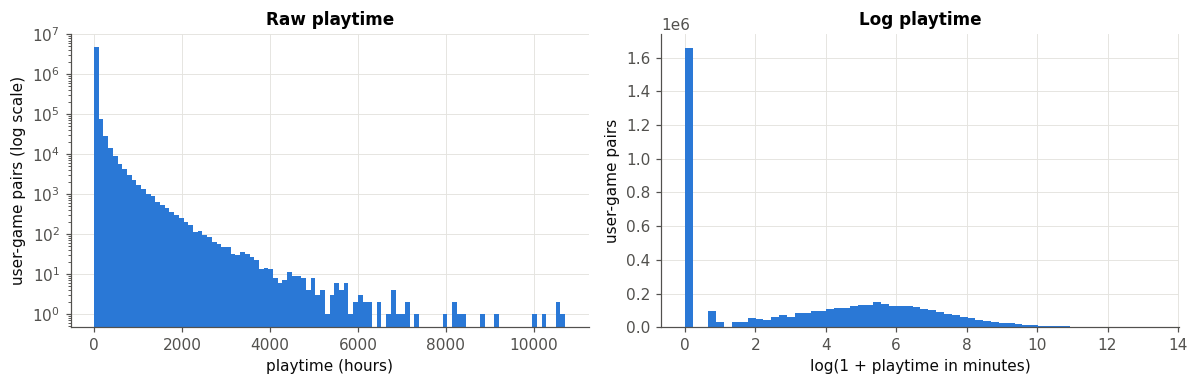

playtime = 0 for 34.11% of owned games
quantiles of playtime (minutes):
0.2500        0.0000
0.5000       42.0000
0.7500      385.0000
0.9000    1,669.0000
0.9900   18,740.0000


In [13]:
pt = interactions['playtime_forever'].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(pt / 60, bins=100, color=COLOR_PRIMARY)
axes[0].set_yscale('log')
axes[0].set_xlabel('playtime (hours)')
axes[0].set_ylabel('user-game pairs (log scale)')
axes[0].set_title('Raw playtime')

axes[1].hist(np.log1p(pt), bins=60, color=COLOR_PRIMARY)
axes[1].set_xlabel('log(1 + playtime in minutes)')
axes[1].set_ylabel('user-game pairs')
axes[1].set_title('Log playtime')
plt.tight_layout()
plt.show()

print(f'playtime = 0 for {np.mean(pt == 0):.2%} of owned games')
print('quantiles of playtime (minutes):')
print(pd.Series(pt).quantile([0.25, 0.5, 0.75, 0.9, 0.99]).to_string())

### Library sizes and game popularity are long-tailed

**Long tails on both sides.** Most users own a modest number of games, but a few own thousands. On the
game side, a handful of titles are owned by tens of thousands of users while most games have only a
few owners. Two things follow from this:
- **Popularity will be a strong baseline for ownership (Task A).** Recommending the few huge games is
  right for a lot of users, so any personalized model has to beat that.
- **Rare games are hard to learn.** Games with only a few owners don't give enough data to learn a good
  embedding. We'll need to decide how much weight these low-owner games get, so they don't just add noise.

**Beta / test duplicates.** Some library entries aren't real separate games. They're betas, test
servers, multiplayer halves or free remasters of another game. For example, *Left 4 Dead 2 Beta* had
exactly the same owners as *Left 4 Dead 2*. Every owner of the main game gets the companion too, so it
would be an easy, free positive for every model and would inflate the scores. We merged these into
their main game in Section 2.3 (step 7), so the table above has no duplicates. Demos are different:
most demo owners don't own the full game, so a demo is a real "tried it" signal and we keep it.

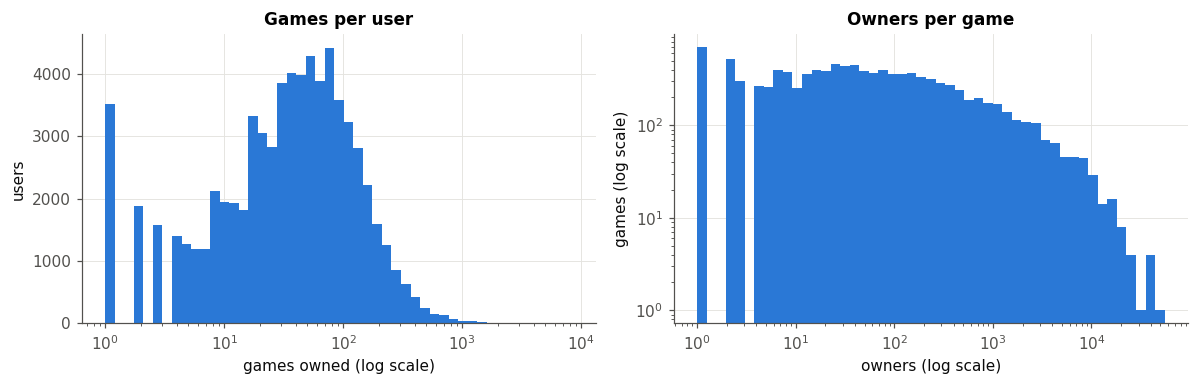

games per user : {'mean': 68.5, '50%': 38.0, 'max': 7587.0}
owners per game: {'mean': 450.2, '50%': 41.0, 'max': 49136.0}


,item_id,game,owners
0,205790,Dota 2 Test,49136
1,730,Counter-Strike: Global Offensive,43331
2,4000,Garry's Mod,42849
3,304930,Unturned,38278
4,550,Left 4 Dead 2,36661
5,105600,Terraria,28934
6,230410,Warframe,25516
7,620,Portal 2,24206
8,240,Counter-Strike: Source,23952
9,218620,PAYDAY 2,23450


In [14]:
gamesPerUser = interactions.groupby('user_id').size()
ownersPerGame = interactions.groupby('item_id').size()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
bins = np.logspace(0, np.log10(gamesPerUser.max()) + 0.05, 50)
axes[0].hist(gamesPerUser, bins=bins, color=COLOR_PRIMARY)
axes[0].set_xscale('log')
axes[0].set_xlabel('games owned (log scale)')
axes[0].set_ylabel('users')
axes[0].set_title('Games per user')

bins = np.logspace(0, np.log10(ownersPerGame.max()) + 0.05, 50)
axes[1].hist(ownersPerGame, bins=bins, color=COLOR_PRIMARY)
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('owners (log scale)')
axes[1].set_ylabel('games (log scale)')
axes[1].set_title('Owners per game')
plt.tight_layout()
plt.show()

print('games per user :', gamesPerUser.describe()[['mean', '50%', 'max']].round(1).to_dict())
print('owners per game:', ownersPerGame.describe()[['mean', '50%', 'max']].round(1).to_dict())
top = ownersPerGame.sort_values(ascending=False).head(10)
storeNames = gamesClean['app_name'].dropna().to_dict()
pd.DataFrame({'item_id': top.index,
              'game': [storeNames.get(i, itemNames.get(i, i)) for i in top.index],
              'owners': top.values})

### `recommend` is heavily imbalanced

**Most reviews recommend the game.** The large majority of reviews are positive, and most reviewing
users recommend every game they review (printed below the plot). So a model that always says
"recommend" already gets high accuracy without learning anything. That makes plain accuracy useless
for Task D.

Instead we use:
- **AUC**, which checks whether the model ranks recommended reviews above not-recommended ones, no
  matter how imbalanced the classes are.
- **Balanced accuracy** ($1 - \text{BER}$ from the Classification lecture), which averages the
  accuracy on each class so the small "not recommended" class counts just as much.
- **Precision, recall and F1 on the "not recommended" class**, since that's the rare class a lazy
  model would miss.

Section 4.1 explains these choices in more detail.

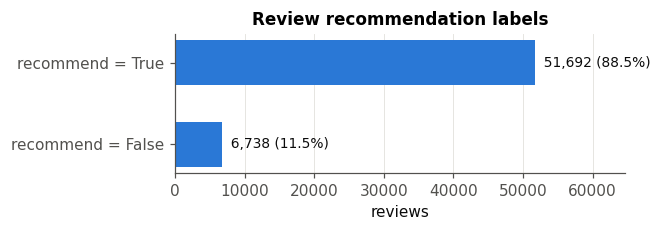

share of reviewing users who recommend every game they review: 80.29%


In [15]:
recCounts = reviews['recommend'].value_counts().reindex([True, False])

fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh(['recommend = True', 'recommend = False'], recCounts.values, color=COLOR_PRIMARY, height=0.55)
for y, v in enumerate(recCounts.values):
    ax.text(v, y, f'  {v:,} ({v / recCounts.sum():.1%})', va='center', color='#0b0b0b', fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('reviews')
ax.set_title('Review recommendation labels')
ax.grid(axis='y', visible=False)
ax.set_xlim(0, recCounts.max() * 1.25)
plt.tight_layout()
plt.show()

perUserRate = reviews.groupby('user_id')['recommend'].mean()
print(f'share of reviewing users who recommend every game they review: {(perUserRate == 1).mean():.2%}')

### Do playtime and `recommend` agree?

We join reviews with the reviewer's library (only reviews of owned games, see Section 2.3) and compare the
explicit label with the implicit "played a lot" label from Section 1.2.

**Playtime and `recommend` agree, but only loosely.** For games the user played a lot, 91.82% of
reviews recommend the game. But 73.94% of reviews for games the user did *not* play a lot are also
positive, so the relationship is positive but far from perfect. Overall the two labels disagree on
19.02% of reviewed games.

The recommend rate is lowest for games played under an hour (64% in the 0-1h bin, see the chart
below) and levels off once playtime passes about 5 hours. This suggests playtime alone can't fully
capture whether a player enjoyed a game, which is why we also check our models against `recommend`
(Section 4.6).


In [16]:
def addRelativePlaytimeLabel(df, includeZeros=True):
    """Label each owned game as 'played a lot' relative to its owner's median playtime.

    Parameters
    ----------
    df : pd.DataFrame
        Interaction table with columns user_id, playtime_forever.
    includeZeros : bool
        If True, the per-user median is taken over all owned games (including never-played ones);
        if False, only over games with playtime > 0.

    Returns
    -------
    pd.DataFrame
        Copy of `df` with added columns `user_median` and `played_a_lot` (bool).
    """
    out = df.copy()
    base = out['playtime_forever'] if includeZeros else out['playtime_forever'].where(out['playtime_forever'] > 0)
    out['user_median'] = base.groupby(out['user_id']).transform('median')
    out['played_a_lot'] = out['playtime_forever'] > out['user_median']
    return out


# Compare both ways of taking the median (Section 1.2): with and without never-played games.
ownedReviews = reviews[reviews['in_library']][['user_id', 'item_id', 'recommend']]
for includeZeros in [True, False]:
    labeled = addRelativePlaytimeLabel(interactions, includeZeros=includeZeros)
    pairs = ownedReviews.merge(labeled[['user_id', 'item_id', 'played_a_lot']], on=['user_id', 'item_id'])
    recRate = pairs.groupby('played_a_lot')['recommend'].mean()
    zeroMedian = (labeled.groupby('user_id')['user_median'].first() == 0).mean()
    print(f'includeZeros={includeZeros!s:5}: played_a_lot share {labeled["played_a_lot"].mean():.2%}, '
          f'users with median 0 {zeroMedian:.2%}, recommend rate high/low '
          f'{recRate.get(True, np.nan):.2%} / {recRate.get(False, np.nan):.2%}')

# Chosen definition (Section 1.2): median over played games only; 0-minute games are always low-play.
interactions = addRelativePlaytimeLabel(interactions, includeZeros=False)
print()
print(f'share of owned games labeled played_a_lot: {interactions["played_a_lot"].mean():.2%}')

joined = reviews[reviews['in_library']].merge(
    interactions[['user_id', 'item_id', 'playtime_forever', 'user_median', 'played_a_lot']],
    on=['user_id', 'item_id'], how='inner')
print(f'reviewed and owned (user, game) pairs     : {len(joined):,}')
print(f'agreement (played_a_lot == recommend)    : {(joined["played_a_lot"] == joined["recommend"]).mean():.2%}')
pd.crosstab(joined['played_a_lot'], joined['recommend'], normalize='index', margins=False).rename_axis(
    index='played_a_lot', columns='recommend')

includeZeros=True : played_a_lot share 46.68%, users with median 0 13.95%, recommend rate high/low 90.63% / 69.21%
includeZeros=False: played_a_lot share 32.51%, users with median 0 0.00%, recommend rate high/low 91.82% / 73.94%

share of owned games labeled played_a_lot: 32.51%
reviewed and owned (user, game) pairs     : 44,185
agreement (played_a_lot == recommend)    : 80.98%


recommend,False,True
played_a_lot,,
False,0.2606,0.7394
True,0.0818,0.9182


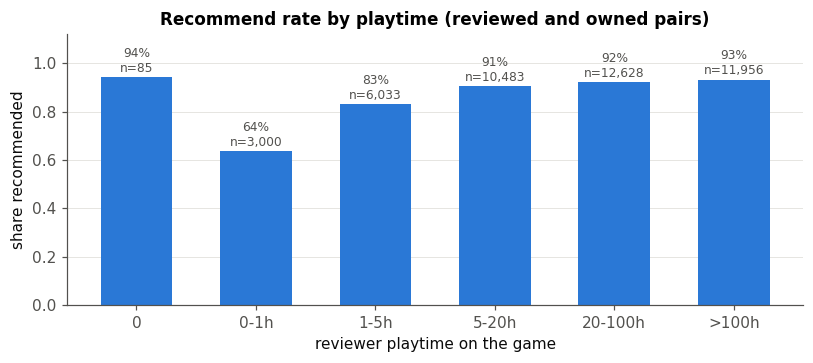

,mean,size
playtime_bin,,
0,0.9412,85
0-1h,0.6370,3000
1-5h,0.8294,6033
5-20h,0.9052,10483
20-100h,0.9226,12628
>100h,0.9313,11956


In [17]:
edges = [-1, 0, 60, 5 * 60, 20 * 60, 100 * 60, np.inf]
labels = ['0', '0-1h', '1-5h', '5-20h', '20-100h', '>100h']
joined['playtime_bin'] = pd.cut(joined['playtime_forever'], bins=edges, labels=labels)
byBin = joined.groupby('playtime_bin', observed=False)['recommend'].agg(['mean', 'size'])

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(byBin.index.astype(str), byBin['mean'], color=COLOR_PRIMARY, width=0.6)
for x, (rate, n) in enumerate(zip(byBin['mean'], byBin['size'])):
    ax.text(x, rate + 0.01, f'{rate:.0%}\nn={n:,}', ha='center', va='bottom', fontsize=8, color='#52514e')
ax.set_ylim(0, 1.12)
ax.set_xlabel('reviewer playtime on the game')
ax.set_ylabel('share recommended')
ax.set_title('Recommend rate by playtime (reviewed and owned pairs)')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()
byBin

In [18]:
# Where do playtime and recommend disagree? Two kinds of disagreement, then by game and by genre.
joined['game'] = joined['item_id'].map(lambda i: displayNames.get(i, i))
joined['playedNotRec'] = joined['played_a_lot'] & ~joined['recommend']   # long playtime, thumbs down
joined['shortButRec'] = ~joined['played_a_lot'] & joined['recommend']    # short playtime, thumbs up
joined['disagree'] = joined['playedNotRec'] | joined['shortButRec']

nDisagree = joined['disagree'].sum()
print(f'disagreement rate                      : {joined["disagree"].mean():.2%}')
print(f'  played a lot, NOT recommended        : {joined["playedNotRec"].mean():.2%} of pairs '
      f'({joined["playedNotRec"].sum() / nDisagree:.0%} of disagreements)')
print(f'  barely played, recommended           : {joined["shortButRec"].mean():.2%} of pairs '
      f'({joined["shortButRec"].sum() / nDisagree:.0%} of disagreements)')

disagreeByGame = joined.groupby('game')['disagree'].sum().sort_values(ascending=False)
print(f'share of disagreements in top 10 games : {disagreeByGame.head(10).sum() / nDisagree:.1%} '
      f'(top 50: {disagreeByGame.head(50).sum() / nDisagree:.1%}, of {joined["game"].nunique():,} reviewed games)')

MIN_GAME_REVIEWS, MIN_GENRE_PAIRS = 100, 300
perGame = joined.groupby('game').agg(reviews=('recommend', 'size'), recommendRate=('recommend', 'mean'),
                                     playedNotRec=('playedNotRec', 'mean'), shortButRec=('shortButRec', 'mean'))
perGame = perGame[perGame['reviews'] >= MIN_GAME_REVIEWS]
print()
print(f'Games with >= {MIN_GAME_REVIEWS} reviews: highest "played a lot, NOT recommended" rate')
display(perGame.sort_values('playedNotRec', ascending=False).head(8))
print(f'Games with >= {MIN_GAME_REVIEWS} reviews: highest "barely played, recommended" rate')
display(perGame.sort_values('shortButRec', ascending=False).head(8))

withGenre = joined.merge(gamesClean['genres'].dropna(), left_on='item_id', right_index=True).explode('genres')
perGenre = withGenre.groupby('genres').agg(pairs=('recommend', 'size'), recommendRate=('recommend', 'mean'),
                                           playedNotRec=('playedNotRec', 'mean'), shortButRec=('shortButRec', 'mean'),
                                           disagree=('disagree', 'mean'))
print(f'Genres with >= {MIN_GENRE_PAIRS} reviewed pairs (a game can have several genres), by disagreement rate')
perGenre[perGenre['pairs'] >= MIN_GENRE_PAIRS].sort_values('disagree', ascending=False)

disagreement rate                      : 19.02%
  played a lot, NOT recommended        : 6.83% of pairs (36% of disagreements)
  barely played, recommended           : 12.18% of pairs (64% of disagreements)
share of disagreements in top 10 games : 14.7% (top 50: 32.5%, of 3,086 reviewed games)

Games with >= 100 reviews: highest "played a lot, NOT recommended" rate


,reviews,recommendRate,playedNotRec,shortButRec
game,,,,
No Man's Sky,115,0.4000,0.4957,0.0174
Call of Duty®: Black Ops III,123,0.6260,0.3496,0.0000
Infestation: Survivor Stories Classic,129,0.4419,0.3333,0.0853
Ace of Spades: Battle Builder,113,0.6372,0.2655,0.0796
H1Z1: Just Survive,155,0.6903,0.2516,0.0581
Robocraft,303,0.7459,0.2244,0.0693
PAYDAY 2,982,0.7892,0.2057,0.0102
Tom Clancy's Ghost Recon Phantoms - NA,122,0.7377,0.2049,0.0410


Games with >= 100 reviews: highest "barely played, recommended" rate


,reviews,recommendRate,playedNotRec,shortButRec
game,,,,
Emily is Away,160,0.9313,0.0063,0.7438
Super Hexagon,139,0.9712,0.0072,0.3597
ORION: Prelude,114,0.8158,0.0526,0.2368
Goat Simulator,247,0.9069,0.0364,0.2186
Fistful of Frags,114,0.9649,0.0263,0.1842
Loadout,259,0.8764,0.0927,0.1815
Realm of the Mad God,187,0.8770,0.0856,0.1390
Hotline Miami,130,1.0000,0.0000,0.1308


Genres with >= 300 reviewed pairs (a game can have several genres), by disagreement rate


,pairs,recommendRate,playedNotRec,shortButRec,disagree
genres,,,,,
Casual,4363,0.8941,0.0394,0.2297,0.2691
Free to Play,6894,0.8467,0.0782,0.1752,0.2534
Indie,18470,0.9039,0.0513,0.1700,0.2212
Sports,863,0.8552,0.0614,0.1576,0.2190
Massively Multiplayer,4117,0.8018,0.1363,0.0714,0.2077
Adventure,11768,0.8966,0.0604,0.1328,0.1932
Early Access,2424,0.8379,0.1068,0.0854,0.1922
Racing,754,0.8873,0.0584,0.1286,0.1870
Simulation,6497,0.9067,0.0502,0.1311,0.1813


**Are the disagreements concentrated?** Not really in a few games: even the top 10 games account for
only a small share of all disagreements (printed above). But the *kind* of disagreement follows a
clear pattern. "Barely played but recommended" is the more common kind, and it shows up in short or
casual games that people enjoy without sinking hours into them (e.g. *Emily is Away*, *Super
Hexagon*), so Casual, Free to Play and Indie have the highest disagreement rates. "Played a lot but
not recommended" clusters in survival, multiplayer and early-access games people grind but end up
disappointed by (e.g. *No Man's Sky*, *H1Z1: Just Survive*, *PAYDAY 2*), and it's highest in Massively Multiplayer
and Early Access. Long genres like RPG and Strategy agree the most. So a playtime-based "fun" model may
underrate short games people love and overrate grindy ones, which we check in Section 4.6.

# 3. Modeling

**What this section is for.** Formulating the tasks as ML problems, presenting each model, and
explaining the design choices and trade-offs. Graders follow this code during the video
walkthrough, so keep each model in its own subsection.

**Rubric: 4 vs. 5.**
- *4:* Inputs, outputs and objective are clear for every model; the advantages and disadvantages
  (complexity, efficiency, implementation challenges) are discussed; the code is walked through.
- *5:* Fun-BPR is well motivated and analyzed (ablations: threshold choice, negative sampling),
  hyperparameters are tuned on validation data with the tuning shown, and scalability is
  discussed with actual timings.

**TODO checklist**
- [ ] Implement `buildIndex`, `splitPerUser` (3.1)
- [ ] Implement the baselines (3.2)
- [ ] Implement the BPR model, samplers and training loop (3.3, 3.4)
- [ ] Implement the latent factor model (3.5)
- [ ] (Optional) TF-IDF + logistic regression for `recommend` (3.6)
- [ ] Tune $K$ and $\lambda$ on the validation split; record the grid and the chosen values
- [ ] Fill in the trade-offs table (3.7) with measured training times

## 3.0 Formulation and course alignment

| Model | Input | Output | Objective | Course material |
|---|---|---|---|---|
| Random | $u$ | random scores | none | trivial baseline |
| Popularity | $u$ | $\#\text{owners}(i)$ or total playtime of $i$ | none | Recommendation lecture; Ethics lecture (`countsPerItem`) |
| BPR | $u$ | $x_{u,i}$ | pairwise log-likelihood, owned vs. unowned | Recommendation lecture ("BPR (implicit)", TensorFlow version from PML ch. 5) |
| **Fun-BPR** (ours) | $u$ | $x_{u,i}$ | pairwise log-likelihood, high-play vs. low-play *owned* | same model as BPR; only the sampling of $(i, j)$ changes |
| Latent factor model | $(u, i)$ | $\hat r_{u,i}$ | regularized MSE on $\log(1+t_{u,i})$ | Recommendation lecture (latent factor models with biases) |
| TF-IDF + logistic regression | review text | $P(\text{recommend})$ | regularized log-likelihood | Text Mining and Classification lectures |

**BPR** scores a (user, game) pair as

$$
x_{u,i} = \beta_i + \gamma_u \cdot \gamma_i ,
$$

and maximizes the probability that a positive game $i$ is ranked above a negative game $j$:

$$
\max_{\Theta} \sum_{(u,i,j) \in D} \ln \sigma\!\left(x_{u,i} - x_{u,j}\right) - \lambda \lVert \Theta \rVert_2^2 .
$$

Standard BPR and Fun-BPR differ only in how the triples $D$ are formed:

| | positive $i$ | negative $j$ |
|---|---|---|
| Standard BPR | $i \in I_u$ (owned) | $j \notin I_u$ (random unowned game) |
| Fun-BPR | $i \in I_u$ with $y^{\text{play}}_{u,i} = 1$ | $j \in I_u$ with $y^{\text{play}}_{u,j} = 0$ |

Because both games in a Fun-BPR triple are owned, popularity (owning) cannot explain the
difference, and the model has to learn which owned games get played.

**Latent factor model** (pointwise regression on log playtime):

$$
\hat r_{u,i} = \alpha + \beta_u + \beta_i + \gamma_u \cdot \gamma_i, \qquad
r_{u,i} = \log(1 + t_{u,i}),
$$

$$
\min_{\alpha, \beta, \gamma} \sum_{(u,i) \in \text{train}} \left(\hat r_{u,i} - r_{u,i}\right)^2
+ \lambda \left( \sum_u \beta_u^2 + \sum_i \beta_i^2 + \sum_u \lVert\gamma_u\rVert_2^2 + \sum_i \lVert\gamma_i\rVert_2^2 \right).
$$

The models follow the lecture code (PML ch. 5): `tf.keras.Model` subclasses with `tf.Variable`
parameters initialized from $\mathcal{N}(0, 0.001^2)$, a `tf.GradientTape` training step and the Adam optimizer.

In [27]:
%pip install tensorflow

   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   - -------------------------------------- 9.2/351.2 MB 45.9 MB/s eta 0:00:08
   -- ------------------------------------- 17.8/351.2 MB 42.5 MB/s eta 0:00:08
   --- ------------------------------------ 27.3/351.2 MB 43.1 MB/s eta 0:00:08
   ---- ----------------------------------- 35.4/351.2 MB 41.8 MB/s eta 0:00:08
   ---- ----------------------------------- 43.3/351.2 MB 40.9 MB/s eta 0:00:08
   ----- ---------------------------------- 50.6/351.2 MB 39.7 MB/s eta 0:00:08
   ------ --------------------------------- 55.3/351.2 MB 37.6 MB/s eta 0:00:08
   ------ --------------------------------- 59.2/351.2 MB 34.9 MB/s eta 0:00:09
   ------- -------------------------------- 62.9/351.2 MB 33.0 MB/s eta 0:00:09
   ------- -------------------------------- 67.4/351.2 MB 31.7 MB/s eta 0:00:09
   -------- ------------------------------- 71.6/351.2 MB 30.7 MB/s eta 0:00:10
   -------- ------------------------------- 77.1/3

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [28]:
import tensorflow as tf

tf.random.set_seed(SEED)
print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


## 3.1 Indexing and train / validation / test split

We split **per user**: for each user with enough games, hold out `nHoldout` positives for
validation and `nHoldout` for test, and keep the rest for training. A random row split could
put all of a user's games in the test set, leaving no training signal for that user.

For Fun-BPR the held-out pairs must contain both a high-play and a low-play owned game, so that
Task B can be evaluated on the same users.

We use `nHoldout = 1` (Section 1.4). A user needs at least 3 high-play and 3 low-play games to be
split; everyone else stays in training only.

TODO: report how many users are kept once `splitPerUser` is implemented.

In [21]:
def buildIndex(interactions):
    """Map raw user and item ids to contiguous integer indices (needed for embedding tables).

    Parameters
    ----------
    interactions : pd.DataFrame
        Interaction table with columns user_id, item_id.

    Returns
    -------
    userIDs : dict
        user_id -> int index in [0, nUsers).
    itemIDs : dict
        item_id -> int index in [0, nItems).
    """
    userIDs = {
        userID: index
        for index, userID in enumerate(interactions['user_id'].unique())
    }
    itemIDs = {
        itemID: index
        for index, itemID in enumerate(interactions['item_id'].unique())
    }
    # TODO: assign indices in order of first appearance (or sorted) for users and items.
    return userIDs, itemIDs


def splitPerUser(interactions, nHoldout=1, minItems=5, seed=SEED):
    """Leave-n-out split per user, stratified on the played_a_lot label.

    Parameters
    ----------
    interactions : pd.DataFrame
        Interaction table with columns user_id, item_id, playtime_forever, played_a_lot.
    nHoldout : int
        Number of high-play and number of low-play owned games held out per user, for each of
        validation and test.
    minItems : int
        Users with fewer owned games than this stay entirely in training.
    seed : int
        Random seed for reproducibility.

    Returns
    -------
    train, valid, test : pd.DataFrame
        Disjoint subsets of `interactions`. Every user in valid/test also appears in train.
    """
    # TODO:
    #   1. group by user; skip users with < minItems games (all their rows go to train)
    #   2. sample nHoldout played_a_lot == True rows and nHoldout == False rows for test,
    #      then the same again (from the remainder) for valid
    #   3. assert every valid/test user still has >= 1 high-play and >= 1 low-play game in train
    rng = np.random.default_rng(seed)
    split = np.zeros(len(interactions), dtype=np.int8)
    labels = interactions['played_a_lot'].to_numpy()
    for userID, positions in interactions.groupby('user_id', sort=False).indices.items():
        if len(positions) < minItems:
            continue
        high = positions[labels[positions] == True]
        low = positions[labels[positions] == False]
        minPerClass = 2 * nHoldout + 1
        if len(high) < minPerClass or len(low) < minPerClass:
            continue
        high = rng.permutation(high)
        low = rng.permutation(low)

        testPositions = np.concatenate([
            high[:nHoldout],
            low[:nHoldout]
        ])
        validPositions = np.concatenate([
            high[nHoldout:2 * nHoldout],
            low[nHoldout:2 * nHoldout]
        ])

        split[testPositions] = 2
        split[validPositions] = 1
        assert np.count_nonzero(split[high] == 0) >= 1
        assert np.count_nonzero(split[low] == 0) >= 1

    train = interactions.iloc[np.flatnonzero(split == 0)].copy()
    valid = interactions.iloc[np.flatnonzero(split == 1)].copy()
    test = interactions.iloc[np.flatnonzero(split == 2)].copy()

    return train, valid, test


# TODO: uncomment once implemented
userIDs, itemIDs = buildIndex(interactions)
train, valid, test = splitPerUser(interactions, nHoldout=1, minItems=5)
print('Number of users:', len(userIDs))
print('Number of games:', len(itemIDs))
print('Training rows:', len(train))
print('Validation rows:', len(valid))
print('Test rows:', len(test))
print('Users included in evaluation:', valid['user_id'].nunique())
train, valid, test = splitPerUser(interactions, nHoldout=1, minItems=5)
print(len(train), len(valid), len(test))

Number of users: 70912
Number of games: 10791
Training rows: 4626445
Validation rows: 115802
Test rows: 115802
Users included in evaluation: 57901
4626445 115802 115802


## 3.2 Baselines: random and popularity

- **Random:** score every game uniformly at random. Gives the chance level for every metric (AUC $\approx 0.5$).
- **Popularity (owned):** $s_{u,i} = |\{v : i \in I_v\}|$, the number of training users owning $i$.
- **Popularity (played):** $s_{u,i} = \sum_v t_{v,i}$ or the share of owners who played $i$ a lot.
  This version is the stronger baseline for Task B.

Neither baseline is personalized. Every user gets the same ranking.

In [26]:
def randomScores(nItems, seed=SEED):
    """Random baseline: one uniform score per item.

    Parameters
    ----------
    nItems : int
        Number of items.
    seed : int
        Random seed.

    Returns
    -------
    np.ndarray of shape (nItems,)
        Scores in [0, 1).
    """
    # TODO
    rng = np.random.default_rng(seed)
    return rng.random(nItems)
scoresRandom = randomScores(len(itemIDs))

print('Number of scores:', len(scoresRandom))
print('First five scores:', scoresRandom[:5])
    


def popularityScores(train, itemIDs, mode='owned'):
    """Non-personalized popularity baseline.

    Parameters
    ----------
    train : pd.DataFrame
        Training interactions with columns item_id, playtime_forever, played_a_lot.
    itemIDs : dict
        item_id -> int index.
    mode : {'owned', 'playtime', 'played_a_lot'}
        'owned' counts owners; 'playtime' sums log(1 + playtime) over owners; 'played_a_lot'
        is the share of owners whose played_a_lot label is True.

    Returns
    -------
    np.ndarray of shape (len(itemIDs),)
        Popularity score per item index (0 for items never seen in train).
    """
    if mode == 'owned':
        itemScores = train.groupby('item_id')['user_id'].nunique()
    elif mode == 'playtime':
        logPlaytime = np.log1p(train['playtime_forever'])
        itemScores = logPlaytime.groupby(train['item_id']).sum()
    elif mode == 'played_a_lot':
        itemScores = train.groupby('item_id')['played_a_lot'].mean()
    else:
        raise ValueError(
            "mode must be 'owned', 'playtime', or 'played_a_lot'"
        )
    scores = np.zeros(len(itemIDs), dtype=float)
    for itemID, itemIndex in itemIDs.items():
        scores[itemIndex] = itemScores.get(itemID, 0.0)
    return scores

scoresOwned = popularityScores(train, itemIDs, mode='owned')
scoresPlaytime = popularityScores(train, itemIDs, mode='playtime')
scoresPlayed = popularityScores(train, itemIDs, mode='played_a_lot')

print('Owned scores:', scoresOwned.shape, scoresOwned[:5])
print('Playtime scores:', scoresPlaytime.shape, scoresPlaytime[:5])
print('Played-a-lot scores:', scoresPlayed.shape, scoresPlayed[:5])

Number of scores: 10791
First five scores: [0.96913147 0.77881772 0.59502895 0.5946204  0.74349167]
Owned scores: (10791,) [8975. 6018. 3291. 3102. 5981.]
Playtime scores: (10791,) [24147.14174912  7881.65521421  3989.70893903  1648.65518527
  8228.58839332]
Played-a-lot scores: (10791,) [0.2005571  0.0485211  0.05742935 0.0106383  0.10700552]


## 3.3 Standard BPR (owned vs. unowned)

In [29]:
class BPRbatch(tf.keras.Model):
    """Bayesian Personalized Ranking with x_ui = beta_i + gamma_u . gamma_i (lecture / PML ch. 5 style).

    Used both for standard BPR and Fun-BPR; only the triples fed to `call` differ.
    """

    def __init__(self, K, lamb, nUsers, nItems):
        """Create the parameters.

        Parameters
        ----------
        K : int
            Latent dimensionality.
        lamb : float
            L2 regularization strength.
        nUsers, nItems : int
            Sizes of the embedding tables.
        """
        super().__init__()
        # TODO: self.betaI  = tf.Variable(tf.random.normal([nItems], stddev=0.001))
        # TODO: self.gammaU = tf.Variable(tf.random.normal([nUsers, K], stddev=0.001))
        # TODO: self.gammaI = tf.Variable(tf.random.normal([nItems, K], stddev=0.001))
        self.lamb = lamb
        self.betaI = self.add_weight(
            name='betaI',
            shape=(nItems,),
            initializer=tf.keras.initializers.RandomNormal(stddev=0.001),
            trainable=True
        )
        self.gammaU = self.add_weight(
            name='gammaU',
            shape=(nUsers, K),
            initializer=tf.keras.initializers.RandomNormal(stddev=0.001),
            trainable=True
        )
        self.gammaI = self.add_weight(
            name='gammaI',
            shape=(nItems, K),
            initializer=tf.keras.initializers.RandomNormal(stddev=0.001),
            trainable=True
        )

    def score(self, sampleU, sampleI):
        """Compute x_ui for a batch of (user, item) index pairs.

        Parameters
        ----------
        sampleU, sampleI : tf.Tensor of int32, shape (B,)
            User and item indices.

        Returns
        -------
        tf.Tensor of float32, shape (B,)
            Scores x_ui.
        """
        # TODO: tf.nn.embedding_lookup for betaI, gammaU, gammaI; return beta_i + sum(gamma_u * gamma_i, axis=1)
        betaI = tf.nn.embedding_lookup(self.betaI, sampleI)
        gammaU = tf.nn.embedding_lookup(self.gammaU, sampleU)
        gammaI = tf.nn.embedding_lookup(self.gammaI, sampleI)

        return betaI + tf.reduce_sum(gammaU * gammaI, axis=1)

    def reg(self):
        """L2 penalty on all parameters.

        Returns
        -------
        tf.Tensor (scalar)
            lamb * (||betaI||^2 + ||gammaU||^2 + ||gammaI||^2).
        """
        # TODO
        return self.lamb * (
            tf.reduce_sum(tf.square(self.betaI))
            + tf.reduce_sum(tf.square(self.gammaU))
            + tf.reduce_sum(tf.square(self.gammaI))
        )

    def call(self, sampleU, sampleI, sampleJ):
        """Negative mean BPR log-likelihood for a batch of triples.

        Parameters
        ----------
        sampleU, sampleI, sampleJ : tf.Tensor of int32, shape (B,)
            Users, positive items, negative items.

        Returns
        -------
        tf.Tensor (scalar)
            -mean(log sigmoid(x_ui - x_uj)).
        """
        # TODO
        positiveScores = self.score(sampleU, sampleI)
        negativeScores = self.score(sampleU, sampleJ)
        difference = positiveScores - negativeScores

        return tf.reduce_mean(tf.nn.softplus(-difference))
# Positive samples come only from training interactions.
itemsPerUser = {
    userIDs[userID]: tuple(itemIDs[itemID] for itemID in group['item_id'])
    for userID, group in train.groupby('user_id', sort=False)
}

# Exclude every known owned game from negative sampling.
allOwnedItemsPerUser = {
    userIDs[userID]: {itemIDs[itemID] for itemID in group['item_id']}
    for userID, group in interactions.groupby('user_id', sort=False)
}


def sampleStandardTriples(itemsPerUser, nItems, nSamples, rng, allOwnedItemsPerUser):
    """Sample (u, i, j) with i owned by u and j a uniformly random game u does NOT own.

    Parameters
    ----------
    itemsPerUser : dict
        user index -> set of owned item indices (training data only).
    nItems : int
        Number of items to sample negatives from.
    nSamples : int
        Batch size.
    rng : random.Random
        Seeded random generator.

    Returns
    -------
    tuple of three lists of int
        sampleU, sampleI, sampleJ.
    """
    # TODO: rejection-sample j until j not in itemsPerUser[u]
    eligibleUsers = [
        userIndex
        for userIndex, items in itemsPerUser.items()
        if len(items) > 0
        and len(allOwnedItemsPerUser[userIndex]) < nItems
    ]

    if not eligibleUsers:
        raise ValueError('No users can form a valid BPR triple.')

    sampleU, sampleI, sampleJ = [], [], []

    for _ in range(nSamples):
        userIndex = rng.choice(eligibleUsers)
        positiveItem = rng.choice(itemsPerUser[userIndex])

        negativeItem = rng.randrange(nItems)
        while negativeItem in allOwnedItemsPerUser[userIndex]:
            negativeItem = rng.randrange(nItems)

        sampleU.append(userIndex)
        sampleI.append(positiveItem)
        sampleJ.append(negativeItem)

    return sampleU, sampleI, sampleJ


def trainingStep(model, optimizer, sampleU, sampleI, sampleJ):
    """One gradient step on a batch of BPR triples.

    Parameters
    ----------
    model : BPRbatch
        The model to update.
    optimizer : tf.keras.optimizers.Optimizer
        e.g. tf.keras.optimizers.Adam(0.1).
    sampleU, sampleI, sampleJ : list of int
        Batch of triples.

    Returns
    -------
    float
        Loss value (including regularization) for this batch.
    """
    # TODO:
    # with tf.GradientTape() as tape:
    #     loss = model(tf.convert_to_tensor(sampleU), ...) + model.reg()
    # grads = tape.gradient(loss, model.trainable_variables)
    # optimizer.apply_gradients(zip(grads, model.trainable_variables))
    sampleU = tf.convert_to_tensor(sampleU, dtype=tf.int32)
    sampleI = tf.convert_to_tensor(sampleI, dtype=tf.int32)
    sampleJ = tf.convert_to_tensor(sampleJ, dtype=tf.int32)

    with tf.GradientTape() as tape:
        loss = model(sampleU, sampleI, sampleJ) + model.reg()

    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))

    return float(loss.numpy())


# TODO: training loop, e.g.
# modelBPR = BPRbatch(K=5, lamb=1e-5, nUsers=len(userIDs), nItems=len(itemIDs))
# optimizer = tf.keras.optimizers.Adam(0.1)
# for step in range(nSteps):
#     batch = sampleStandardTriples(itemsPerUser, len(itemIDs), 50000, rng)
#     loss = trainingStep(modelBPR, optimizer, *batch)
import time

tf.keras.utils.set_random_seed(SEED)
rng = random.Random(SEED)

modelBPR = BPRbatch(
    K=5,
    lamb=1e-5,
    nUsers=len(userIDs),
    nItems=len(itemIDs)
)
optimizerBPR = tf.keras.optimizers.Adam(learning_rate=0.01)

nSteps = 200
batchSize = 4096
lossesBPR = []

print('Trainable parameter arrays:', len(modelBPR.trainable_variables))

startTime = time.perf_counter()

for step in range(nSteps):
    batch = sampleStandardTriples(
        itemsPerUser,
        len(itemIDs),
        batchSize,
        rng,
        allOwnedItemsPerUser
    )

    loss = trainingStep(modelBPR, optimizerBPR, *batch)
    lossesBPR.append(loss)

    if step == 0 or (step + 1) % 20 == 0:
        print(f'Step {step + 1}/{nSteps}, loss: {loss:.4f}')

trainingTimeBPR = time.perf_counter() - startTime
print(f'Training time: {trainingTimeBPR:.2f} seconds')

Trainable parameter arrays: 3
Step 1/200, loss: 0.6931
Step 20/200, loss: 0.5968
Step 40/200, loss: 0.5153
Step 60/200, loss: 0.4508
Step 80/200, loss: 0.4034
Step 100/200, loss: 0.3635
Step 120/200, loss: 0.3352
Step 140/200, loss: 0.3214
Step 160/200, loss: 0.3084
Step 180/200, loss: 0.2980
Step 200/200, loss: 0.2929
Training time: 13.93 seconds


## 3.4 Fun-BPR (high-play vs. low-play, both owned)

Same `BPRbatch` model, different triples. The item bias $\beta_i$ now learns "games that tend to
be played a lot by their owners" instead of "games that are owned a lot".

TODO: ablations. (a) median vs. top-quartile threshold; (b) including vs. excluding zero-playtime games
as negatives; (c) initializing from standard BPR then fine-tuning on fun triples.

In [ ]:
def buildFunSets(train, userIDs, itemIDs):
    """Split each user's owned training games into high-play and low-play sets.

    Parameters
    ----------
    train : pd.DataFrame
        Training interactions with columns user_id, item_id, played_a_lot.
    userIDs, itemIDs : dict
        Raw id -> int index.

    Returns
    -------
    dict
        user index -> (list of high-play item indices, list of low-play item indices). Users
        missing either list are excluded, since they cannot form a triple.
    """
    # TODO
    raise NotImplementedError


def sampleFunTriples(funSets, nSamples, rng):
    """Sample (u, i, j) with i a high-play and j a low-play game, both owned by u.

    Parameters
    ----------
    funSets : dict
        Output of `buildFunSets`.
    nSamples : int
        Batch size.
    rng : random.Random
        Seeded random generator.

    Returns
    -------
    tuple of three lists of int
        sampleU, sampleI, sampleJ.
    """
    # TODO: sample u uniformly from funSets (or proportional to library size; discuss), then i, j
    raise NotImplementedError


# TODO: modelFun = BPRbatch(...); train with sampleFunTriples and the same trainingStep

## 3.5 Latent factor model on log playtime

In [ ]:
class LatentFactorModel(tf.keras.Model):
    """r_hat(u, i) = alpha + beta_u + beta_i + gamma_u . gamma_i, fit to log(1 + playtime)."""

    def __init__(self, mu, K, lamb, nUsers, nItems):
        """Create the parameters.

        Parameters
        ----------
        mu : float
            Initial value of the global offset alpha (use the training mean of log(1 + t)).
        K : int
            Latent dimensionality.
        lamb : float
            L2 regularization strength.
        nUsers, nItems : int
            Sizes of the bias and embedding tables.
        """
        super().__init__()
        # TODO: self.alpha = tf.Variable(mu)
        # TODO: self.betaU, self.betaI, self.gammaU, self.gammaI (stddev=0.001)
        self.lamb = lamb

    def predict(self, u, i):
        """Predict log playtime for a single (user index, item index) pair.

        Parameters
        ----------
        u, i : int
            User and item indices.

        Returns
        -------
        float
            Predicted log(1 + playtime).
        """
        # TODO
        raise NotImplementedError

    def reg(self):
        """L2 penalty on biases and latent factors.

        Returns
        -------
        tf.Tensor (scalar)
        """
        # TODO
        raise NotImplementedError

    def call(self, sampleU, sampleI, sampleR):
        """Mean squared error on a batch.

        Parameters
        ----------
        sampleU, sampleI : tf.Tensor of int32, shape (B,)
            User and item indices.
        sampleR : tf.Tensor of float32, shape (B,)
            Targets log(1 + playtime).

        Returns
        -------
        tf.Tensor (scalar)
            Mean squared error.
        """
        # TODO
        raise NotImplementedError


# TODO: train with a GradientTape step analogous to `trainingStep`, early-stop on validation MSE.
# Note: this model can also rank games for Task B by its predicted playtime; evaluate it there too.

## 3.6 (Optional) TF-IDF + logistic regression on review text

Predict `recommend` from the review text. Labels are imbalanced, so use
`class_weight='balanced'` (the lecture's way of optimizing a balanced error measure) and evaluate
with AUC and balanced accuracy, not accuracy.

In [ ]:
def trainRecommendClassifier(trainTexts, trainLabels, maxFeatures=5000, C=1.0):
    """Fit TF-IDF features + logistic regression to predict `recommend`.

    Parameters
    ----------
    trainTexts : list of str
        Review texts.
    trainLabels : list of bool
        `recommend` labels.
    maxFeatures : int
        Vocabulary size (most frequent terms).
    C : float
        Inverse regularization strength for LogisticRegression.

    Returns
    -------
    vectorizer : sklearn.feature_extraction.text.TfidfVectorizer
        Fitted vectorizer.
    clf : sklearn.linear_model.LogisticRegression
        Fitted classifier.
    """
    # TODO:
    # from sklearn.feature_extraction.text import TfidfVectorizer
    # from sklearn.linear_model import LogisticRegression
    # vectorizer = TfidfVectorizer(max_features=maxFeatures, lowercase=True)
    # clf = LogisticRegression(C=C, class_weight='balanced', max_iter=1000)
    raise NotImplementedError

## 3.7 Trade-offs

| | Random / Popularity | BPR / Fun-BPR (pairwise) | Latent factor model (pointwise) | TF-IDF + LR |
|---|---|---|---|---|
| Personalized | no | yes | yes | per review |
| Objective matches ranking metrics | n/a | yes (AUC is the pairwise objective) | no (MSE) | n/a |
| Uses playtime magnitude | optional | only through the label threshold | yes | no |
| Parameters | $O(\lvert I\rvert)$ | $O((\lvert U\rvert + \lvert I\rvert)K)$ | $O((\lvert U\rvert + \lvert I\rvert)(K+1))$ | $O(\text{vocabulary})$ |
| Cost per epoch | $O(\text{interactions})$ | $O(\text{samples} \cdot K)$ + negative sampling | $O(\text{interactions} \cdot K)$ | sparse matrix ops |
| Cold start | handles new users | fails for new users/games | fails for new users/games | needs text |
| Training time (measured) | TODO | TODO | TODO | TODO |

**Discussion points (TODO: write up):**
- *Pointwise vs. pairwise.* MSE treats every owned game as a regression target and is dominated by
  heavy players, while BPR only cares about order, which is what a recommender shows the user.
- *Implicit feedback.* Unowned does not mean disliked, so BPR's negatives are only "less preferred".
  Fun-BPR's negatives are informative because the user owns the game and chose not to play it.
- *Efficiency.* Negative sampling keeps BPR linear in the number of sampled triples instead of $\lvert U\rvert \cdot \lvert I\rvert$.

# 4. Evaluation

**What this section is for.** Justifying the metrics, implementing the evaluation protocol,
comparing every model with the baselines, and checking that the predictions are valid.

**Rubric: 4 vs. 5.**
- *4:* Metrics justified relative to the alternatives, baselines included, a results table and plots,
  and negative results explained.
- *5:* Both protocols (Task A and Task B) are reported for every model, with confidence intervals and
  paired significance tests against the baselines, a breakdown by user segment (e.g. small vs. large
  libraries), and a convincing validity check against explicit `recommend` labels.

**TODO checklist**
- [ ] Implement the metric functions (4.2) and test them on toy inputs with known answers
- [ ] Run all models on validation for tuning, then **once** on test
- [ ] Fill in the results table (4.3) from code, not by hand
- [ ] Significance (4.4): run both comparisons, Fun-BPR vs. BPR **and** Fun-BPR vs. Popularity (played), on Task B and Task A
- [ ] Plots (4.5): metric vs. $K$, metric by library size
- [ ] Validity check (4.6)

## 4.1 Metrics and why

**AUC** (covered in the Recommendation lecture). For user $u$ with held-out positives $P_u$ and negatives $N_u$:

$$
\text{AUC}(u) = \frac{1}{\lvert P_u\rvert\,\lvert N_u\rvert} \sum_{i \in P_u} \sum_{j \in N_u} \mathbb{1}\left[x_{u,i} > x_{u,j}\right],
\qquad
\text{AUC} = \frac{1}{\lvert U\rvert} \sum_u \text{AUC}(u).
$$

It counts the fraction of correctly ordered pairs (0.5 = random, 1.0 = perfect), which is exactly what
BPR optimizes, and it does not require negatives to be "disliked", only less preferred.

**Hit@K**, for Task A only (the Recommendation lecture's **Recall@K**, slides 148-150; with a single
held-out positive per user the two are the same number). Rank the candidate games for $u$; a hit
occurs if the held-out game $i_u$ appears in the top $K$:

$$
\text{Hit@}K = \frac{1}{\lvert U\rvert} \sum_u \mathbb{1}\left[\operatorname{rank}_u(i_u) \le K\right].
$$

It matches what a user actually sees (a top-10 list) and is easy to explain: was the game in the top 10?
It is also one of the two metrics SASRec reports on Steam (Section 5), so our Task A numbers are comparable.

**Why Task B uses AUC only.** In Task B the candidates are the user's held-out *owned* games, which with
`nHoldout = 1` is just two games (one high-play, one low-play). A top-10 list of two games always
contains the right one, so Hit@10 would be 1 for every model. AUC asks the only question that makes sense
here: did the model put the high-play game above the low-play one?

**Why not NDCG@K.** The lecture names NDCG but leaves it to the textbook (slide 147). It mainly adds
credit for rank 1 over rank 10, which Hit@10 ignores. We keep two ranking metrics so the results stay
easy to read, and AUC already rewards ranking the held-out game high among all candidates.

**MSE on $\log(1 + t)$** for Task C. The lecture shows MSE is sensitive to outliers. The log transform
(see the skew in Section 2.4) keeps a few extreme players from dominating.

**Balanced accuracy / BER** for `recommend`. The Classification lecture defines the Balanced Error
Rate $\text{BER} = \tfrac12(\text{FPR} + \text{FNR})$; balanced accuracy is $1 - \text{BER}$. Since most
reviews recommend the game (see the share printed in Section 2.3), always predicting `True` already
gets that share as plain accuracy while learning nothing; its BER is $0.5$, the same as random. AUC
is reported as well because it does not depend on a decision threshold.

**Sampled vs. full ranking.** Ranking against all ~10k games per user is expensive. A common shortcut is to rank the held-out game
against 100 sampled unowned games. Sampled metrics can change model orderings
(Krichene & Rendle, KDD 2020), so TODO: report at least one full-ranking result for comparison.

## 4.2 Evaluation protocol

- **Task A (ownership):** candidates = held-out owned game(s) + sampled unowned games, ranked by $x_{u,i}$.
- **Task B (fun):** candidates = held-out **owned** games only; positives are high-play, negatives low-play.
- **Task C (playtime):** MSE of predicted vs. actual $\log(1 + t)$ on held-out owned pairs.

Every model is scored on every applicable protocol, including the baselines, so the comparison is fair.

In [ ]:
def aucForUser(posScores, negScores):
    """AUC for one user: fraction of (positive, negative) pairs ordered correctly (ties count 0.5).

    Parameters
    ----------
    posScores : array-like of float
        Model scores of the user's held-out positive items.
    negScores : array-like of float
        Model scores of the user's negative items.

    Returns
    -------
    float
        AUC in [0, 1].
    """
    # TODO
    raise NotImplementedError


def hitAtK(rankedItems, relevantItems, K=10):
    """Hit@K: 1 if any relevant item is in the top K of the ranking, else 0.

    Parameters
    ----------
    rankedItems : list of int
        Candidate item indices sorted by descending score.
    relevantItems : set of int
        Held-out positive item indices.
    K : int
        Cutoff.

    Returns
    -------
    float
        1.0 or 0.0.
    """
    # TODO
    raise NotImplementedError


def balancedAccuracy(yTrue, yPred):
    """Balanced accuracy = 1 - BER = mean of the true positive rate and the true negative rate.

    Parameters
    ----------
    yTrue, yPred : array-like of bool
        Ground-truth and predicted labels.

    Returns
    -------
    float
        Balanced accuracy in [0, 1].
    """
    # TODO
    raise NotImplementedError


def mse(yTrue, yPred):
    """Mean squared error.

    Parameters
    ----------
    yTrue, yPred : array-like of float

    Returns
    -------
    float
    """
    # TODO
    raise NotImplementedError


def evaluateRanking(scoreFn, heldOut, itemsPerUserTrain, nItems, task='A', K=10, nNegatives=100, seed=SEED):
    """Run the Task A or Task B ranking protocol for one model.

    Parameters
    ----------
    scoreFn : callable
        scoreFn(userIndex, np.ndarray of itemIndices) -> np.ndarray of scores.
    heldOut : dict
        user index -> dict with keys 'pos' (list of item indices) and, for Task B, 'neg'.
    itemsPerUserTrain : dict
        user index -> set of item indices owned in training (excluded from Task A negatives).
    nItems : int
        Total number of items.
    task : {'A', 'B'}
        'A': negatives are sampled unowned games; 'B': negatives are held-out low-play owned games.
    K : int
        Cutoff for Hit@K (Task A only).
    nNegatives : int
        Number of sampled negatives per user for Task A.
    seed : int
        Random seed for negative sampling (use the same seed for every model).

    Returns
    -------
    dict
        {'AUC': float, 'Hit@K': float, 'nUsers': int} for Task A and {'AUC': float, 'nUsers': int} for
        Task B (two candidates per user, so Hit@K is not meaningful there), averaged over users, plus
        'perUser': dict metric name -> np.ndarray of per-user values, ordered by sorted user index
        (needed by the paired significance tests in Section 4.4; every model must use the same user order).
    """
    # TODO
    raise NotImplementedError

## 4.3 Results

TODO: populate `results` from code (one row per model, one column per metric). Report mean
$\pm$ std over at least 3 seeds. Bold the best value in each column in the write-up.

In [ ]:
models = ['Random', 'Popularity (owned)', 'Popularity (played)', 'BPR', 'Fun-BPR', 'Latent factor (log playtime)']
metrics = ['A: AUC', 'A: Hit@10', 'B: AUC', 'C: MSE']
results = pd.DataFrame(np.nan, index=models, columns=metrics)

# TODO: results.loc['BPR', 'A: AUC'] = evaluateRanking(...)['AUC'], etc.
results  # placeholder: every NaN must be filled from code before submission

,A: AUC,A: Hit@10,A: NDCG@10,B: AUC,B: Hit@10,B: NDCG@10,C: MSE
Random,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Popularity (owned),NaN,NaN,NaN,NaN,NaN,NaN,NaN
Popularity (played),NaN,NaN,NaN,NaN,NaN,NaN,NaN
BPR,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fun-BPR,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Latent factor (log playtime),NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4.4 Statistical significance

*The lectures ask "are our results statistically significant?" but do not teach a specific test, so we
explain the method here.*

A results table on its own does not show that one model is better than another: a 0.01 AUC gap could just
be the luck of which games were held out. Every metric here is an **average over test users**, so we
treat users as the unit of sampling and ask how much that average would change on a different sample of users.

**1. Confidence intervals (percentile bootstrap).** Resample the $n$ test users with replacement $B$ times
(here $B = 2000$), recompute the mean metric $\bar m^{*}_b$ on each resample, and report the 2.5th and 97.5th
percentiles of $\{\bar m^{*}_b\}$ as a 95% CI. No normality assumption is needed, which matters because
per-user Hit@10 is binary and per-user AUC is bounded and skewed.

**2. Paired test between two models.** Models A and B are evaluated on the **same users with the same
sampled negatives**, so we compare the per-user differences $d_u = m_u^{A} - m_u^{B}$. Pairing removes the
user-to-user variation (some users are simply easy) and is far more powerful than comparing two
independent CIs. We test $H_0: \mathbb{E}[d] = 0$ two ways:
- *Paired bootstrap:* bootstrap CI of $\bar d$. The p-value is the share of resampled means, centered on the
  null, at least as far from 0 as the observed $\bar d$:
  $p = \frac{1}{B}\sum_b \mathbb{1}\left[\,\lvert \bar d^{*}_b - \bar d\rvert \ge \lvert \bar d\rvert\,\right]$.
- *Wilcoxon signed-rank test* (non-parametric cross-check). For a binary metric like Hit@10 the nonzero
  differences are all $\pm 1$, so it reduces to a sign test (equivalent in spirit to McNemar's test).

**3. Multiple comparisons (Holm).** We compare several models against the best baseline on several
metrics. With 20 tests at $\alpha = 0.05$, about one "significant" result is expected by chance alone. The
Holm-Bonferroni procedure sorts the $m$ p-values $p_{(1)} \le \dots \le p_{(m)}$ and rejects while
$p_{(k)} \le \alpha / (m - k + 1)$. It controls the family-wise error rate and is uniformly more powerful than
plain Bonferroni.

**4. Seed variance.** Bootstrap CIs capture variation over users but not over training randomness
(initialization, negative sampling). Retrain each model with at least 3 seeds and report mean $\pm$ std.
A difference smaller than the seed std is not a real improvement, even if a single run's p-value is small.

**Statistical vs. practical significance.** With tens of thousands of test users even tiny gaps become
"significant". Always report the effect size (the CI of $\bar d$), not just the p-value.

### Which comparisons we run (team plan)

**In plain words:** each test user gets a score under each model. We look at the per-user differences
between two models and ask: "If we had tested on different users, would the winner still win?" The
bootstrap answers this by re-sampling our own users 2,000 times. **If the 95% interval of the difference
does not include 0, the difference is real, not luck.**

We make **two separate claims**, so we run **two comparisons** with the same per-user scores and a different `reference`:

| # | Comparison | Question it answers | If it fails |
|---|---|---|---|
| 1 | Fun-BPR vs. **BPR** | Does our new training idea (played-a-lot vs. barely-played, both owned) beat normal BPR (owned vs. not owned)? | Our main idea did not help. |
| 2 | Fun-BPR vs. **Popularity (played)** | Is the model worth anything beyond "recommend what most people play a lot"? | Personalization adds nothing; beating BPR alone would not mean much. |

We use **Popularity (played)** as the baseline because it is the strongest simple baseline for the "fun" task.

**Run both comparisons on both tasks, and report the results honestly:**
- **Task B (rank owned games by "fun"):** we expect Fun-BPR to win both comparisons. This is our main result.
- **Task A (predict ownership):** we expect **normal BPR** to beat Fun-BPR, because that is what it is
  trained for (hypothesis H2). If so, report it as each model doing well at what it was trained for.
  Do not hide it.

**Template sentence for the video** (fill in from the tables; do not guess numbers):
> "On the fun task, Fun-BPR beats normal BPR by X AUC (95% CI [...]) and the popularity baseline by Y
> (95% CI [...]); both are significant after Holm correction. On the ownership task, normal BPR wins, as expected."

In [ ]:
from scipy import stats


def bootstrapCI(perUserValues, nBoot=2000, alpha=0.05, seed=SEED, chunk=200):
    """Percentile bootstrap confidence interval for the mean of a per-user metric.

    Parameters
    ----------
    perUserValues : array-like of float
        One metric value per test user (e.g. per-user AUC or 0/1 Hit@10).
    nBoot : int
        Number of bootstrap resamples.
    alpha : float
        1 - confidence level (0.05 gives a 95% CI).
    seed : int
        Random seed.
    chunk : int
        Resamples drawn per batch, which bounds memory to chunk * nUsers indices.

    Returns
    -------
    tuple of float
        (mean, ciLow, ciHigh).
    """
    x = np.asarray(perUserValues, dtype=float)
    rng = np.random.default_rng(seed)
    means = np.empty(nBoot)
    for start in range(0, nBoot, chunk):
        size = min(chunk, nBoot - start)
        idx = rng.integers(0, len(x), size=(size, len(x)))
        means[start:start + size] = x[idx].mean(axis=1)
    low, high = np.quantile(means, [alpha / 2, 1 - alpha / 2])
    return float(x.mean()), float(low), float(high)


def pairedBootstrapTest(valuesA, valuesB, nBoot=2000, alpha=0.05, seed=SEED, chunk=200):
    """Paired bootstrap test of H0: mean(A - B) = 0 over the same users.

    Parameters
    ----------
    valuesA, valuesB : array-like of float
        Per-user metric values of models A and B, aligned so index k is the same user in both.
    nBoot : int
        Number of bootstrap resamples.
    alpha : float
        1 - confidence level for the CI of the mean difference.
    seed : int
        Random seed.
    chunk : int
        Resamples drawn per batch.

    Returns
    -------
    dict
        {'meanDiff', 'ciLow', 'ciHigh', 'pValue'}: the mean of A - B, its bootstrap CI, and the
        two-sided p-value (null-centered bootstrap; the smallest reportable value is 1 / nBoot).
    """
    a = np.asarray(valuesA, dtype=float)
    b = np.asarray(valuesB, dtype=float)
    assert a.shape == b.shape, 'models must be evaluated on the same users in the same order'
    d = a - b
    rng = np.random.default_rng(seed)
    means = np.empty(nBoot)
    for start in range(0, nBoot, chunk):
        size = min(chunk, nBoot - start)
        idx = rng.integers(0, len(d), size=(size, len(d)))
        means[start:start + size] = d[idx].mean(axis=1)
    observed = d.mean()
    pValue = max(np.mean(np.abs(means - observed) >= abs(observed)), 1 / nBoot)
    low, high = np.quantile(means, [alpha / 2, 1 - alpha / 2])
    return {'meanDiff': float(observed), 'ciLow': float(low), 'ciHigh': float(high), 'pValue': float(pValue)}


def wilcoxonTest(valuesA, valuesB):
    """Wilcoxon signed-rank test on paired per-user values (zero differences are dropped).

    Parameters
    ----------
    valuesA, valuesB : array-like of float
        Per-user metric values of models A and B, aligned by user.

    Returns
    -------
    float
        Two-sided p-value (1.0 if every paired difference is zero).
    """
    d = np.asarray(valuesA, dtype=float) - np.asarray(valuesB, dtype=float)
    if np.all(d == 0):
        return 1.0
    return float(stats.wilcoxon(d, zero_method='wilcox', alternative='two-sided').pvalue)


def holmCorrection(pValues):
    """Holm-Bonferroni adjusted p-values (controls the family-wise error rate).

    Parameters
    ----------
    pValues : array-like of float
        Raw p-values from m tests.

    Returns
    -------
    np.ndarray of float
        Adjusted p-values in the original order; reject H0 where adjusted p <= alpha.
    """
    p = np.asarray(pValues, dtype=float)
    m = len(p)
    order = np.argsort(p)
    adjusted = np.empty(m)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i])  # step-down; keep adjusted p-values monotone
        adjusted[i] = min(running, 1.0)
    return adjusted


def compareModels(perUserByModel, reference, alpha=0.05, nBoot=2000, seed=SEED):
    """Compare every model with a reference model (e.g. the best baseline) on one metric.

    Parameters
    ----------
    perUserByModel : dict
        model name -> per-user metric array (same users, same order for every model).
    reference : str
        Name of the model to compare against.
    alpha : float
        Significance level after Holm correction.
    nBoot : int
        Bootstrap resamples.
    seed : int
        Random seed.

    Returns
    -------
    pd.DataFrame
        One row per model: mean, 95% CI, mean difference vs. reference with its CI, bootstrap and Wilcoxon
        p-values, Holm-adjusted bootstrap p-value, and whether the difference is significant.
    """
    rows = []
    for name, values in perUserByModel.items():
        mean, low, high = bootstrapCI(values, nBoot=nBoot, seed=seed)
        row = {'model': name, 'mean': mean, 'ci95': f'[{low:.4f}, {high:.4f}]'}
        if name != reference:
            test = pairedBootstrapTest(values, perUserByModel[reference], nBoot=nBoot, seed=seed)
            row.update({'diff vs ref': test['meanDiff'],
                        'diff ci95': f'[{test["ciLow"]:+.4f}, {test["ciHigh"]:+.4f}]',
                        'p (bootstrap)': test['pValue'],
                        'p (Wilcoxon)': wilcoxonTest(values, perUserByModel[reference])})
        rows.append(row)
    table = pd.DataFrame(rows).set_index('model')
    tested = table['p (bootstrap)'].notna()
    table['p (Holm)'] = np.nan
    table.loc[tested, 'p (Holm)'] = holmCorrection(table.loc[tested, 'p (bootstrap)'])
    table['significant'] = np.where(tested, table['p (Holm)'] <= alpha, None)
    return table


def seedSummary(resultsPerSeed):
    """Mean and standard deviation of each metric across training seeds.

    Parameters
    ----------
    resultsPerSeed : list of dict
        One dict per seed, mapping metric name -> value (e.g. {'B: AUC': 0.71, ...}).

    Returns
    -------
    pd.DataFrame
        Rows are metrics; columns 'mean', 'std', 'nSeeds'.
    """
    df = pd.DataFrame(resultsPerSeed)
    return pd.DataFrame({'mean': df.mean(), 'std': df.std(ddof=1), 'nSeeds': df.count()})

### Sanity check on synthetic data (NOT results)

The cell below checks the functions above on **made-up per-user scores where the right answer is known**:
- `model A` is better than the reference by construction (+0.02 mean shift),
- `model B` has the same expected score as the reference (it only adds noise).

So A should come out significant and B should not. Delete this cell, or keep it as a documented test, once
real per-user arrays from `evaluateRanking(...)['perUser']` are available.

In [ ]:
_rng = np.random.default_rng(0)
_nUsers = 3000
_reference = _rng.beta(6, 3, size=_nUsers)  # stand-in for per-user AUC
_synthetic = {
    'reference (synthetic)': _reference,
    'model A: +0.02 (synthetic)': np.clip(_reference + 0.02 + _rng.normal(0, 0.05, _nUsers), 0, 1),
    'model B: no effect (synthetic)': np.clip(_reference + _rng.normal(0, 0.05, _nUsers), 0, 1),
}
print('SYNTHETIC DEMO, NOT RESULTS')
compareModels(_synthetic, reference='reference (synthetic)')

SYNTHETIC DEMO, NOT RESULTS


,mean,ci95,diff vs ref,diff ci95,p (bootstrap),p (Wilcoxon),p (Holm),significant
model,,,,,,,,
reference (synthetic),0.6689,"[0.6639, 0.6745]",NaN,NaN,NaN,NaN,NaN,None
model A: +0.02 (synthetic),0.6895,"[0.6840, 0.6951]",0.0206,"[+0.0187, +0.0224]",0.0005,0.0000,0.0010,True
model B: no effect (synthetic),0.6686,"[0.6632, 0.6743]",-0.0003,"[-0.0021, +0.0015]",0.7630,0.7626,0.7630,False


In [ ]:
# Holm correction on a textbook example: p = [0.01, 0.04, 0.03, 0.005] -> adjusted [0.03, 0.06, 0.06, 0.02]
assert np.allclose(holmCorrection([0.01, 0.04, 0.03, 0.005]), [0.03, 0.06, 0.06, 0.02])
print('holmCorrection matches the textbook example')

# Seed summary on a toy input: mean 0.70, std 0.01
assert np.isclose(seedSummary([{'m': 0.69}, {'m': 0.70}, {'m': 0.71}]).loc['m', 'std'], 0.01)
print('seedSummary matches the toy example')

# TODO (real results): the two comparisons from the team plan above, on both tasks.
# for task in ['B', 'A']:
#     perUser = {name: evaluateRanking(scoreFns[name], heldOutTest, itemsPerUserTrain, len(itemIDs),
#                                      task=task)['perUser']['AUC']
#                for name in scoreFns}
#     print(f'Task {task}, comparison 1: is our training idea better than normal BPR?')
#     display(compareModels(perUser, reference='BPR'))
#     print(f'Task {task}, comparison 2: is it better than the strongest simple baseline?')
#     display(compareModels(perUser, reference='Popularity (played)'))
#     # For Task A, repeat with 'Hit@K' in place of 'AUC'.
#
# seedSummary([...one results dict per seed...])

holmCorrection matches the textbook example
seedSummary matches the toy example


## 4.5 Plots

TODO:
- Metric vs. latent dimensionality $K$ for BPR and Fun-BPR (validation).
- Task B AUC by user library size (quartiles): does personalization help more for big libraries?
- Training loss curves.

## 4.6 Validity check: does "fun" match `recommend`?

1. For users who reviewed games they own, score those games with Fun-BPR (trained **without** the
   review labels). Is the AUC of Fun-BPR scores at separating recommended from not-recommended games above 0.5?
2. Compare with standard BPR and popularity on the same pairs.
3. **Disagreements:** list games with high relative playtime but a low recommend rate ("grindy"
   games) and the reverse (short but loved). Use `gamesClean` genres/tags to characterize them.

In [ ]:
def recommendAgreement(scoreFn, joined, userIDs, itemIDs):
    """AUC of model scores at separating recommended from not-recommended reviewed, owned games.

    Parameters
    ----------
    scoreFn : callable
        scoreFn(userIndex, np.ndarray of itemIndices) -> np.ndarray of scores.
    joined : pd.DataFrame
        Reviewed and owned pairs (Section 2.4) with columns user_id, item_id, recommend.
    userIDs, itemIDs : dict
        Raw id -> int index.

    Returns
    -------
    dict
        {'AUC': float, 'nUsers': int}, over users with both a recommended and a not-recommended game.
    """
    # TODO: per user, aucForUser(scores of recommended games, scores of not-recommended games)
    raise NotImplementedError


def playtimeRecommendDisagreement(joined, minReviews=20):
    """Per-game comparison of the implicit and explicit "fun" signals.

    Parameters
    ----------
    joined : pd.DataFrame
        Reviewed and owned pairs with columns item_id, recommend, played_a_lot.
    minReviews : int
        Only games with at least this many reviews are reported.

    Returns
    -------
    pd.DataFrame
        One row per game: n_reviews, recommend_rate, played_a_lot_rate, gap
        (= played_a_lot_rate - recommend_rate), sorted by gap.
    """
    # TODO
    raise NotImplementedError

# 5. Related Work

**What this section is for.** Placing our dataset, task and results in context.

**Rubric: 4 vs. 5.**
- *4:* Covers how this dataset (and similar ones) has been used, how prior work approached similar
  tasks, and how our results compare.
- *5:* Engages with the papers' actual methods and numbers, explains differences in protocol,
  and borrows ideas from them explicitly.

**TODO checklist**
- [ ] Read the three Steam papers below and fill in each block
- [ ] Add the general method references we rely on
- [ ] Write the "comparison with our results" paragraph once Section 4 is done

### Wan & McAuley, "Item Recommendation on Monotonic Behavior Chains", RecSys 2018 (most relevant)
- *Dataset use:* TODO
- *Idea:* user feedback forms a chain of increasingly strong signals (e.g. purchase -> play -> review -> recommend);
  observing a later stage implies the earlier ones. TODO: summarize the model.
- *Relation to us:* Fun-BPR uses one link of this chain (owned -> played a lot), and the validity check uses the
  next (-> recommended). TODO: compare.

### Kang & McAuley, "Self-Attentive Sequential Recommendation" (SASRec), ICDM 2018
- *Dataset use:* TODO (which Steam data, which preprocessing)
- *Approach:* sequential next-item prediction with self-attention. TODO
- *Relation to us:* we ignore order; TODO: discuss what sequence information would add, and their evaluation protocol (Hit@10 / NDCG@10 with sampled negatives).

### Pathak, Gupta & McAuley, "Generating and Personalizing Bundle Recommendations on Steam", SIGIR 2017
- *Dataset use:* TODO (bundle data, user-item interactions)
- *Approach:* TODO (BPR-style models for bundles)
- *Relation to us:* TODO

### Method references (suggested)
- Rendle et al., "BPR: Bayesian Personalized Ranking from Implicit Feedback", UAI 2009.
- Koren, Bell & Volinsky, "Matrix Factorization Techniques for Recommender Systems", IEEE Computer 2009.
- Hu, Koren & Volinsky, "Collaborative Filtering for Implicit Feedback Datasets", ICDM 2008, which uses consumption
  amount (like playtime) as confidence. TODO: decide whether to include it as a comparison.
- Krichene & Rendle, "On Sampled Metrics for Item Recommendation", KDD 2020 (relevant to Section 4.1).

### How our results compare
TODO: once Section 4 is complete, compare our numbers and conclusions with the papers above, noting protocol differences.

# 6. Conclusion

**TODO checklist**
- [ ] Findings: answer H1-H3 from Section 1.3 with numbers referenced from Section 4
- [ ] Limitations
- [ ] Future work

## Findings
TODO

## Limitations
- TODO (e.g. playtime is a noisy proxy: idle time, free-to-play grinding, games bought in bundles and never opened)
- TODO (only Australian users; a single snapshot in time; reviews of games no longer in the library)

## Future work
- TODO (e.g. use the full monotonic chain, sequence models, genre/tag features for cold start)

# 7. Export to HTML

Submission checklist:
1. *Kernel -> Restart & Run All*. Confirm there are no errors and every output and plot is visible.
2. Remove leftover `NotImplementedError` stubs and the "Team conventions" block in Section 0.
3. Save the notebook.
4. Export with the command below (from a terminal in this folder, or uncomment the cell and run it).
   This produces a real HTML file starting with `<!DOCTYPE html>`. **Renaming the `.ipynb` file does not work.**
5. Run the check cell after it, then open `workbook.html` in a browser.
6. Submit `workbook.html` and `video_url.txt` (one line: a Google Drive "anyone with the link" mp4 URL, or a YouTube link).

The export line is commented out so that *Run All* does not export a half-saved notebook.

In [ ]:
# !jupyter nbconvert --to html assignment2.ipynb --output workbook.html

In [ ]:
def checkWorkbookHtml(path='workbook.html'):
    """Check the exported file the same way the autograder does.

    Parameters
    ----------
    path : str
        Path to the exported HTML file.

    Returns
    -------
    bool
        True if the file exists and starts with '<!DOCTYPE html>'.
    """
    if not os.path.exists(path):
        print(f'{path} not found: export first.')
        return False
    with open(path, 'r', encoding='utf-8') as f:
        ok = f.read().startswith('<!DOCTYPE html>')
    print(f'{path}: ' + ('OK, starts with <!DOCTYPE html>' if ok else 'NOT a valid export'))
    return ok


checkWorkbookHtml()

workbook.html not found: export first.


False